# LiTRA multi-band XGBoost pipeline — training, evaluation and C export

This notebook extends the original single-file optimiser so that it ingests **several raw
benchmark captures at once** (one capture per CPU frequency band), harmonises them into a
single training corpus, and then reports a complete machine-learning evaluation suite for
Chapter 5: class balance, data split, cross-validation, confusion matrices, per-class
precision/recall/F1, ROC and precision-recall curves, feature importance, learning curve,
cross-band generalisation and baseline comparison.

Every table is written as CSV and every figure as PNG and SVG at 300 dpi under `chapter5_out/`,
together with `chapter5_results.md`, which contains the same tables in Markdown for pasting
into the dissertation. The C/H exporter of the original notebook is preserved unchanged in
behaviour, so `xgb_model.c` and `xgb_model.h` remain drop-in replacements for the ESP32-P4 build.

**Order of execution:** run the cells from top to bottom. Cell 2 is where the raw CSV paths are declared.

**Revision.** Section 10a compares nine model families before any tuning, 10b measures the untuned
boosted ensemble as the reference, 11a sweeps depth, learning rate and rounds one at a time, and 19a
selects the deployment point under a flash budget instead of on accuracy. The search grid now spans
the region the library defaults occupy, which the earlier grid excluded.


In [1]:
# 1) Environment
!pip install xgboost -q
import os, json, glob, zipfile, shutil, itertools, warnings, textwrap, math
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")

import matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "figure.autolayout": True,
})

import xgboost as X
from sklearn.model_selection import (StratifiedKFold, train_test_split,
                                     cross_val_predict, learning_curve)
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             classification_report, roc_curve, auc,
                             precision_recall_curve, average_precision_score,
                             balanced_accuracy_score, cohen_kappa_score,
                             matthews_corrcoef, log_loss)
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
print("xgboost", X.__version__)

xgboost 3.4.1


## 2) Raw captures

The firmware emits head­erless `RESULT` lines with 29 fields. Declare one entry per capture;
the key is the label that will identify the band throughout the report. If a file already
carries a header row it is detected and dropped automatically.

In [2]:
# 2) Declare the raw captures (label -> path). Add or remove entries freely.
DATASETS = {
    "20 MHz":  "client-20.csv",
    "40 MHz":  "client-40.csv",
    "90 MHz":  "client-90.csv",
    "180 MHz": "client-180.csv",
    "360 MHz": "client-360.csv",
}

try:
    from google.colab import files
    IN_COLAB = True
except Exception:
    IN_COLAB = False

missing = [p for p in DATASETS.values() if not os.path.exists(p)]
if IN_COLAB and missing:
    print("Upload:", missing)
    up = files.upload()
    for k, v in list(DATASETS.items()):          # tolerate Colab name mangling
        if not os.path.exists(v):
            cand = [u for u in up if os.path.basename(v).split('.')[0] in u]
            if cand: DATASETS[k] = cand[0]

for k, v in DATASETS.items():
    print(f"{k:>8} -> {v}  exists={os.path.exists(v)}")

  20 MHz -> client-20.csv  exists=True
  40 MHz -> client-40.csv  exists=True
  90 MHz -> client-90.csv  exists=True
 180 MHz -> client-180.csv  exists=True
 360 MHz -> client-360.csv  exists=True


In [3]:
# 3) Configuration
OUT_DIR   = "chapter5_out"
FIG_DIR   = os.path.join(OUT_DIR, "figures")
TBL_DIR   = os.path.join(OUT_DIR, "tables")
MODEL_DIR = os.path.join(OUT_DIR, "models")
for d in (OUT_DIR, FIG_DIR, TBL_DIR, MODEL_DIR): os.makedirs(d, exist_ok=True)

SPLIT_SEED, MODEL_SEED, CV_FOLDS = 50, 42, 5
TEST_SIZE = 0.20

# Label construction scope:
#   "global"            one Fast/Medium/Slow terciling over the whole corpus
#   "per_freq"          terciles computed inside each frequency band
#   "per_freq_payload"  terciles computed inside each (band, payload) cell  <- recommended
LABEL_SCOPE = "per_freq_payload"

INCLUDE_FREQ_FEATURE = False   # Chapter 4 specifies 18 features; the clock is not one    # expose cpu_freq_mhz to the model (the node knows its own clock)
ENABLE_LEARNING_CURVE = True
ENABLE_PERMUTATION    = True
ENABLE_LOBO           = True   # leave-one-band-out generalisation study
ENABLE_BASELINES      = True

# Some captures carry a file name that disagrees with the clock field, or a handful of
# records logged before the frequency switch settled. Rows whose clock differs from the
# dominant value of their own capture are dropped and counted; CLOCK_OVERRIDE then restates
# the dominant value where the firmware reported the wrong figure.
DROP_CLOCK_MISMATCH = True
CLOCK_OVERRIDE = {}

QUICK_MODE = False             # True -> small grid, for a smoke test
SEARCH_N_ESTIMATORS = 250
SWEEP_MAX_ROUNDS    = 300
SWEEP_STEP          = 20
# The truncation front is swept over its own list of depths, independently of PARAM_GRID.
# The grid searches for accuracy and therefore explores deep trees; the front has to cover
# the small end, where every deployable configuration lives.
SWEEP_DEPTHS        = [2, 3, 4, 5, 6]
SWEEP_LR            = 0.30     # rate used for every depth on the front (child weight 1)
EXPORT_ROUNDS       = 100      # Chapter 4 deployment point
ACC_TOLERANCE       = 0.005
FLASH_BUDGET_KB     = 256      # deployment points are selected under this budget, not on accuracy
ENABLE_FAMILY_STUDY = True     # section 10a: nine model families at default settings
ENABLE_SWEEPS       = True     # section 11a: one-parameter-at-a-time sweeps
INCLUDE_BASELINE_C  = True
NCLS, DEFAULT_WEIGHT = 3, 0.5
CLASS_NAMES = ["Good", "Medium", "Bad"]

# The earlier grid stopped at depth 4 and a rate of 0.10, while the library defaults sit
# at depth 6 and a rate of 0.30. The searched model therefore never entered the region the
# untuned reference occupies, which is why it scored below it. The grid now spans that
# region; the split penalty is dropped because it moved accuracy by under a tenth of a point.
PARAM_GRID = {
    "max_depth":        [4, 6, 8],
    "learning_rate":    [0.1, 0.2, 0.3],
    "min_child_weight": [1, 5],
    "reg_lambda":       [2.0],
}
if QUICK_MODE:
    PARAM_GRID = {"max_depth": [3], "learning_rate": [0.1],
                  "min_child_weight": [1], "gamma": [0.0], "reg_lambda": [2.0]}
    SEARCH_N_ESTIMATORS, SWEEP_MAX_ROUNDS, SWEEP_STEP = 60, 60, 20

# Energy is not measured by the firmware. It is reconstructed as an analytical proxy:
#   E_proxy (mJ) = P_ACTIVE_MW * cycles_mean / (cpu_freq_mhz * 1e6)
# Replace P_ACTIVE_MW with a measured figure before quoting absolute energy in the thesis.
P_ACTIVE_MW = 90.0

# Selection pool. AES-128-GCM and ChaCha20-Poly1305 stay in the measurement tables as
# references; only the NIST LWC finalists are selectable at run time.
CANDIDATE_SUITES = ["ASCON-128", "TinyJAMBU", "GIFT-COFB", "Grain-128AEADv2", "Schwaemm"]
REFERENCE_SUITES = ["AES-128-GCM", "ChaCha20-Poly1305"]

# FEATURE_PRIORITY is the priority vector. It defines the composite score the tiers are cut
# from. Its multiplicative role in the scaler has no effect on a tree ensemble (a monotone
# per-feature transform), so it acts through the labels alone; see the profile study below.
FEATURE_PRIORITY = {
    "lat_per_byte": (3.0, +1), "E_lat_per_byte": (3.0, +1), "cycles_per_bit": (3.0, +1),
    "throughput": (3.0, -1), "Energy": (2.5, +1), "stack_per_msg": (2.0, +1),
    "cpu_freq_mhz": (2.0, -1),
    "latency": (1.0, +1), "E_latency": (1.0, +1), "cycles_mean": (1.0, +1),
    "payload_size": (1.0, +1),
    "heap_per_msg": (0.5, +1), "Flash_used": (0.5, +1), "Ex_code": (0.5, +1),
    "rodata": (0.5, +1), "total_memory": (0.5, +1),
    "cv_latency": (0.3, +1), "lat_per_byte_std": (0.3, +1), "E_lat_per_byte_std": (0.3, +1),
}

RAW29 = ["model_name","cores","chip_revision","cpu_freq_mhz","total_ram","cipher_suite",
         "payload_size","num_messages","client_ts","server_ts","read_ts","mean_latency",
         "std_latency","cv_latency","lat_per_byte_mean","lat_per_byte_std",
         "mean_write_latency","write_lat_per_byte_mean","write_lat_per_byte_std",
         "cycles_mean","throughput","cycles_per_bit","cpu_ticks_per_msg","heap_per_msg",
         "stack_per_msg","flash","code","rodata","total_memory"]

RENAME = {"mean_latency":"latency", "lat_per_byte_mean":"lat_per_byte",
          "mean_write_latency":"E_latency", "write_lat_per_byte_mean":"E_lat_per_byte",
          "write_lat_per_byte_std":"E_lat_per_byte_std",
          "flash":"Flash_used", "code":"Ex_code"}

CIPHER_CANON = {
    "chacha20-poly1305": "TLS_CHACHA20_POLY1305_SHA256",
    "chacha20poly1305":  "TLS_CHACHA20_POLY1305_SHA256",
    "aes-128-gcm":       "TLS_AES_128_GCM_SHA256",
}
CIPHER_SHORT = {
    "TLS_AES_128_GCM_SHA256":"AES-128-GCM", "TLS_CHACHA20_POLY1305_SHA256":"ChaCha20-Poly1305",
    "LTLS_ASCON_128_SHA256":"ASCON-128", "LTLS_TINY_128_SHA256":"TinyJAMBU",
    "LTLS_GIF_128_SHA256":"GIFT-COFB", "LTLS_GRN_128_SHA256":"Grain-128AEADv2",
    "LTLS_SHWM_128_SHA256":"Schwaemm", "TLS_SHA256_SHA256":"Null-AEAD (SHA256)",
}
print("configuration loaded | label scope:", LABEL_SCOPE)

configuration loaded | label scope: per_freq_payload


In [4]:
# 4) Reporting helpers
REPORT = []          # markdown blocks for chapter5_results.md
RESULTS = {}         # machine-readable summary

def save_table(df, name, caption, index=False, floatfmt=4):
    path = os.path.join(TBL_DIR, name + ".csv")
    df.to_csv(path, index=index)
    REPORT.append("### " + caption + "\n\n" +
                  df.round(floatfmt).to_markdown(index=index) + "\n\n_Source: `tables/" +
                  name + ".csv`_\n")
    return path

def save_fig(fig, name, caption):
    for ext in ("png", "svg"):
        fig.savefig(os.path.join(FIG_DIR, name + "." + ext), bbox_inches="tight")
    REPORT.append("### " + caption + "\n\n![" + caption + "](figures/" + name + ".png)\n")
    plt.show(); plt.close(fig)

def plot_confusion(cm, title, name, caption, classes=None, normalise=False):
    classes = classes or CLASS_NAMES
    M = cm.astype(float)
    if normalise:
        rs = M.sum(1, keepdims=True); rs[rs == 0] = 1; M = M / rs
    fig, ax = plt.subplots(figsize=(4.6, 4.0))
    im = ax.imshow(M, cmap="Blues", vmin=0, vmax=M.max() if M.max() > 0 else 1)
    ax.set_xticks(range(len(classes)), classes, rotation=20, ha="right")
    ax.set_yticks(range(len(classes)), classes)
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class"); ax.set_title(title)
    ax.grid(False)
    thr = M.max() / 2 if M.max() > 0 else 0.5
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            txt = ("{:.1%}".format(M[i, j]) if normalise else "{:d}".format(int(cm[i, j])))
            ax.text(j, i, txt, ha="center", va="center", fontsize=9,
                    color="white" if M[i, j] > thr else "black")
    fig.colorbar(im, ax=ax, fraction=0.046, shrink=0.85,
                 label="Share of true class" if normalise else "Samples")
    save_fig(fig, name, caption)

def metric_block(y_true, y_pred, proba=None, tag=""):
    d = {"accuracy": accuracy_score(y_true, y_pred),
         "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
         "f1_macro": f1_score(y_true, y_pred, average="macro"),
         "f1_weighted": f1_score(y_true, y_pred, average="weighted"),
         "cohen_kappa": cohen_kappa_score(y_true, y_pred),
         "mcc": matthews_corrcoef(y_true, y_pred)}
    if proba is not None:
        try: d["log_loss"] = log_loss(y_true, proba, labels=list(range(NCLS)))
        except Exception: pass
    RESULTS[tag] = {k: float(v) for k, v in d.items()}
    return d
print("helpers ready")

helpers ready


## 5) Ingestion and harmonisation

Each capture is read without a header, the 29 field names of the firmware `HEADER` line are
applied, and the records are normalised: `180MHz` style clock strings are reduced to integers,
board identifiers and cipher-suite spellings are canonicalised, and physically impossible rows
(zero or negative latency, zero payload, non-finite throughput) are removed and counted.

In [5]:
# 5) Load, harmonise and audit
def load_raw(path, band):
    df = pd.read_csv(path, header=None, names=RAW29, dtype=str,
                     skip_blank_lines=True, on_bad_lines="skip")
    df = df[df["cipher_suite"].notna()]
    df = df[~df["model_name"].astype(str).str.upper().str.startswith("HEADER")]
    df = df[df["model_name"].astype(str).str.lower() != "model_name"]   # literal header row
    df["source_file"] = os.path.basename(path)
    df["band"] = band
    return df

frames, load_log = [], []
for band, path in DATASETS.items():
    d = load_raw(path, band); n0 = len(d)
    d["cpu_freq_mhz"] = pd.to_numeric(
        d["cpu_freq_mhz"].astype(str).str.replace(r"[^0-9.]", "", regex=True), errors="coerce")
    d["model_name"] = d["model_name"].astype(str).str.lower().str.replace("-", "", regex=False)
    cs = d["cipher_suite"].astype(str).str.strip()
    d["cipher_suite"] = cs.str.lower().map(CIPHER_CANON).fillna(cs)
    for c in RAW29:
        if c not in ("model_name", "cipher_suite"):
            d[c] = pd.to_numeric(d[c], errors="coerce")
    modal = d["cpu_freq_mhz"].mode()
    modal = float(modal.iloc[0]) if len(modal) else np.nan
    mism = int((d["cpu_freq_mhz"] != modal).sum())
    if DROP_CLOCK_MISMATCH and np.isfinite(modal):
        d = d[d["cpu_freq_mhz"] == modal]
    if band in CLOCK_OVERRIDE:
        d["cpu_freq_mhz"] = float(CLOCK_OVERRIDE[band])
    bad_lat  = (~(d["mean_latency"] > 0)).sum()
    bad_pay  = (~(d["payload_size"] > 0)).sum()
    bad_thr  = (~np.isfinite(d["throughput"])).sum()
    d = d[(d["mean_latency"] > 0) & (d["payload_size"] > 0) & np.isfinite(d["throughput"])]
    d = d[d["cycles_mean"] > 0]
    load_log.append({"band": band, "file": os.path.basename(path), "rows_read": n0,
                     "dropped_latency": int(bad_lat), "dropped_payload": int(bad_pay),
                     "dropped_throughput": int(bad_thr), "dropped_clock_mismatch": mism,
                     "rows_kept": len(d),
                     "clock_MHz": ", ".join(str(int(v)) for v in sorted(d["cpu_freq_mhz"].dropna().unique()))})
    frames.append(d)

raw = pd.concat(frames, ignore_index=True)
qual = pd.DataFrame(load_log)
save_table(qual, "tbl_5_1_ingestion_audit", "Table 5.1 Ingestion and validity audit for the five captures")
display(qual)
print("merged corpus:", raw.shape)

,band,file,rows_read,dropped_latency,dropped_payload,dropped_throughput,dropped_clock_mismatch,rows_kept,clock_MHz
0,20 MHz,client-20.csv,16830,0,0,0,0,16830,20
1,40 MHz,client-40.csv,17127,0,0,0,80,17047,40
2,90 MHz,client-90.csv,21440,0,0,0,0,21440,90
3,180 MHz,client-180.csv,16354,0,0,0,0,16354,180
4,360 MHz,client-360.csv,16887,0,0,0,0,16887,360


merged corpus: (88558, 31)


In [6]:
# 6) Coverage of the merged corpus
raw["cipher"] = raw["cipher_suite"].map(CIPHER_SHORT).fillna(raw["cipher_suite"])

cov = pd.crosstab(raw["cipher"], raw["band"])
cov = cov[[b for b in DATASETS if b in cov.columns]]
cov.loc["TOTAL"] = cov.sum()
save_table(cov.reset_index(), "tbl_5_2_band_cipher_matrix",
           "Table 5.2 Records per cipher suite and clock band after cleaning", index=False)
display(cov)

pay = pd.crosstab(raw["payload_size"], raw["band"])
save_table(pay.reset_index(), "tbl_5_3_payload_matrix",
           "Table 5.3 Records per payload size and clock band", index=False)

thin = [f"{c} @ {b}" for b in cov.columns for c in cov.index[:-1] if cov.loc[c, b] == 0]
if thin:
    print("WARNING - empty cipher/band cells, these bands cannot support cipher ranking:")
    for t in thin: print("   ", t)
    REPORT.append("**Coverage warning.** The following cipher/band combinations carry no "
                  "records: " + "; ".join(thin) + ".\n")

band,20 MHz,40 MHz,90 MHz,180 MHz,360 MHz
cipher,,,,,
AES-128-GCM,2100,2100,1757,1925,2100
ASCON-128,2130,2100,5143,2272,2178
ChaCha20-Poly1305,2100,2100,3850,2100,2100
GIFT-COFB,2100,2100,2133,2100,2109
Grain-128AEADv2,2100,2097,2100,1225,2100
Null-AEAD (SHA256),2100,2316,2100,2211,2100
Schwaemm,2100,2134,2257,2289,2100
TinyJAMBU,2100,2100,2100,2232,2100
TOTAL,16830,17047,21440,16354,16887


In [7]:
# 7) Feature construction and cleaning
def build_features(df):
    d = df.rename(columns=RENAME).copy()
    d["Energy"] = P_ACTIVE_MW * d["cycles_mean"] / (d["cpu_freq_mhz"] * 1e6)
    keep = [c for c in FEATURE_PRIORITY if c in d.columns]
    if not INCLUDE_FREQ_FEATURE and "cpu_freq_mhz" in keep:
        keep.remove("cpu_freq_mhz")
    meta = ["band", "cipher", "cipher_suite", "source_file", "payload_size", "cpu_freq_mhz"]
    out = d[sorted(set(keep + meta), key=lambda c: (c not in keep, c))].copy()
    return out, keep

def clean(df, feats):
    d = df.copy()
    d[feats] = d[feats].replace([np.inf, -np.inf], np.nan)
    for c in feats:
        d.loc[d[c] < 0, c] = np.nan
    outl = [c for c in ["latency","lat_per_byte","E_lat_per_byte","E_latency","throughput",
                        "cycles_per_bit","cycles_mean","Energy","stack_per_msg",
                        "heap_per_msg","total_memory"] if c in feats]
    clipped = {}
    for c in outl:                      # IQR clipping inside each (band, payload) cell
        before = d[c].copy()
        def _clip(s):
            s = s.astype(float)
            if s.notna().sum() < 8 or s.nunique() < 4: return s
            q1, q3 = s.quantile(.25), s.quantile(.75); i = q3 - q1
            return s if i == 0 else s.clip(q1 - 1.5*i, q3 + 1.5*i)
        d[c] = d.groupby(["band", "payload_size"])[c].transform(_clip)
        clipped[c] = int((before != d[c]).sum())
    for c in feats:
        if d[c].isna().any():
            m = d.groupby("band")[c].transform("median")
            d[c] = d[c].fillna(m).fillna(d[c].median()).fillna(0.0)
    const = [c for c in feats if d[c].nunique(dropna=False) <= 1]
    if const:
        print("dropped constant features:", const)
        d = d.drop(columns=const); feats = [c for c in feats if c not in const]
    return d, feats, clipped

feat_df, FEATS = build_features(raw)
feat_df, FEATS, clip_log = clean(feat_df, FEATS)
clip_tbl = pd.DataFrame({"feature": list(clip_log), "values_clipped": list(clip_log.values())})
clip_tbl["share_%"] = (100 * clip_tbl["values_clipped"] / len(feat_df)).round(2)
save_table(clip_tbl, "tbl_5_4_outlier_clipping",
           "Table 5.4 Values adjusted by within-cell interquartile clipping")
print(f"features ({len(FEATS)}):", FEATS)
print("-> the features[] array on the ESP32-P4 must follow exactly this order.")

features (18): ['lat_per_byte', 'E_lat_per_byte', 'cycles_per_bit', 'throughput', 'Energy', 'stack_per_msg', 'latency', 'E_latency', 'cycles_mean', 'payload_size', 'heap_per_msg', 'Flash_used', 'Ex_code', 'rodata', 'total_memory', 'cv_latency', 'lat_per_byte_std', 'E_lat_per_byte_std']
-> the features[] array on the ESP32-P4 must follow exactly this order.


## 8) Label construction

The performance class is derived from a weighted, min-max normalised composite of the
priority features. With `LABEL_SCOPE = "per_freq_payload"` the terciles are computed inside
each (band, payload) cell, so a label answers the question the runtime classifier actually
faces: *given this clock and this payload, is the cipher currently in use fast, moderate or slow?*
A global terciling would instead encode the clock frequency itself, since every 40 MHz record
would fall into the slow tercile regardless of the cipher.

performance_class,Good,Medium,Bad,total
band,,,,
180 MHz,5455,5446,5453,16354
20 MHz,5614,5602,5614,16830
360 MHz,5633,5622,5632,16887
40 MHz,5687,5675,5685,17047
90 MHz,7148,7146,7146,21440
ALL,29537,29491,29530,88558


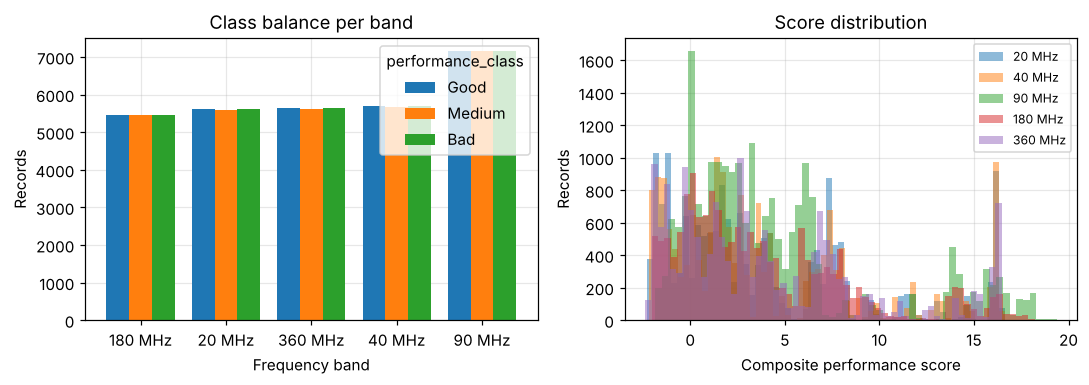

'chapter5_out/tables/tbl_5_6_class_by_cipher.csv'

In [8]:
# 8) Composite score -> Fast / Medium / Slow
def minmax(s):
    s = pd.to_numeric(s, errors="coerce").astype(float)
    lo, hi = s.min(), s.max()
    if not np.isfinite(lo) or not np.isfinite(hi) or hi == lo:
        return pd.Series(np.zeros(len(s)), index=s.index)
    return (s - lo) / (hi - lo)

def composite(d):
    score = pd.Series(0.0, index=d.index)
    for c, (w, sign) in FEATURE_PRIORITY.items():
        if c in d.columns:
            score = score + sign * w * minmax(d[c]).fillna(0.0)
    return score.replace([np.inf, -np.inf], np.nan)

def tercile(s):
    s = s.fillna(s.median())
    try:
        return pd.qcut(s, 3, labels=CLASS_NAMES, duplicates="drop").astype(str)
    except ValueError:
        return pd.qcut(s.rank(method="first"), 3, labels=CLASS_NAMES).astype(str)

df = feat_df.copy()
if LABEL_SCOPE == "global":
    df["_composite_score"] = composite(df)
    df["performance_class"] = tercile(df["_composite_score"])
else:
    keys = ["band"] if LABEL_SCOPE == "per_freq" else ["band", "payload_size"]
    df["_composite_score"] = np.nan; df["performance_class"] = ""
    for _, idx in df.groupby(keys).groups.items():
        sub = df.loc[idx]
        sc = composite(sub)
        df.loc[idx, "_composite_score"] = sc.values
        df.loc[idx, "performance_class"] = tercile(sc).values
df = df[df["performance_class"].isin(CLASS_NAMES)].reset_index(drop=True)

dist = (df.groupby(["band", "performance_class"]).size().unstack(fill_value=0)
          .reindex(columns=CLASS_NAMES, fill_value=0))
dist["total"] = dist.sum(1); dist.loc["ALL"] = dist.sum()
save_table(dist.reset_index(), "tbl_5_5_class_distribution",
           "Table 5.5 Class distribution per clock band", index=False)
display(dist)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
d2 = dist.drop(index="ALL").drop(columns="total")
d2.plot(kind="bar", ax=ax[0], width=0.8)
ax[0].set_ylabel("Records"); ax[0].set_xlabel("Frequency band")
ax[0].set_title("Class balance per band"); ax[0].tick_params(axis="x", rotation=0)
for b in df["band"].unique():
    ax[1].hist(df.loc[df.band == b, "_composite_score"], bins=60, alpha=0.5, label=b)
ax[1].set_xlabel("Composite performance score"); ax[1].set_ylabel("Records")
ax[1].set_title("Score distribution"); ax[1].legend(fontsize=8)
save_fig(fig, "fig_5_1_class_distribution",
         "Figure 5.1 Class balance and composite-score distribution")

crosstab = pd.crosstab(df["cipher"], df["performance_class"]).reindex(columns=CLASS_NAMES, fill_value=0)
save_table(crosstab.reset_index(), "tbl_5_6_class_by_cipher",
           "Table 5.6 Tier assignment per cipher suite", index=False)

In [9]:
# 9) Split and scaling
y_txt = df["performance_class"]
le = LabelEncoder()
le.classes_ = np.array(CLASS_NAMES, dtype=object)   # keep the declared order, not alphabetical
yy = le.transform(y_txt)
Xdf = df[FEATS].astype(np.float32)
NFEAT = Xdf.shape[1]
print("label map:", dict(enumerate(le.classes_)))

idx = np.arange(len(df))
itr, ite = train_test_split(idx, test_size=TEST_SIZE, random_state=SPLIT_SEED, stratify=yy)
Xtr, Xte = Xdf.iloc[itr], Xdf.iloc[ite]
ytr, yte = yy[itr], yy[ite]
meta_te = df.iloc[ite][["band", "cipher", "payload_size"]].reset_index(drop=True)

def fit_scaler(A):
    cols = list(A.columns)
    mn, mx = A.min().to_numpy(np.float32), A.max().to_numpy(np.float32)
    wt = np.array([FEATURE_PRIORITY.get(c, (DEFAULT_WEIGHT, 1))[0] for c in cols], np.float32)
    return cols, mn, mx, wt

def apply_scaler(A, mn, mx, wt):
    M = A.to_numpy(np.float32); rng = (mx - mn).copy(); rng[rng == 0] = 1.0
    return (np.clip((M - mn) / rng, 0, 1) * wt).astype(np.float32)

COLS, MN, MX, WT = fit_scaler(Xtr)
Str, Ste = apply_scaler(Xtr, MN, MX, WT), apply_scaler(Xte, MN, MX, WT)
dm_te = X.DMatrix(Ste)

split_tbl = pd.DataFrame([
    {"subset": "training", "records": len(itr),
     **{c: int((ytr == i).sum()) for i, c in enumerate(le.classes_)}},
    {"subset": "test", "records": len(ite),
     **{c: int((yte == i).sum()) for i, c in enumerate(le.classes_)}}])
split_tbl["share_%"] = (100 * split_tbl["records"] / len(df)).round(1)
save_table(split_tbl, "tbl_5_7_split",
           f"Table 5.7 Stratified split into training and test sets")
display(split_tbl)

label map: {0: 'Good', 1: 'Medium', 2: 'Bad'}


,subset,records,Good,Medium,Bad,share_%
0,training,70846,23629,23593,23624,80.0
1,test,17712,5908,5898,5906,20.0


In [10]:
# 10) C exporter (unchanged output format: xgb_model.c / xgb_model.h)
def f32(x): return float(np.float32(x))
def _fmtf(x):
    s = f"{np.float32(x):.9g}"
    if not any(c in s for c in ".eEni"): s += ".0"
    return s + "f"
def _parse_tree(tj, nodes):
    def add(nd):
        i = len(nodes); nodes.append(None)
        if "leaf" in nd: nodes[i] = (-1, f32(nd["leaf"]), -1, -1)
        else:
            f = int(nd["split"][1:]); thr = f32(nd["split_condition"])
            ch = {c["nodeid"]: c for c in nd["children"]}
            l = add(ch[nd["yes"]]); r = add(ch[nd["no"]]); nodes[i] = (f, thr, l, r)
        return i
    return add(json.loads(tj))
def compute_base(booster, probe):
    marg = booster.predict(X.DMatrix(probe.reshape(1, -1)), output_margin=True)[0]
    ts = [0.0] * NCLS
    for t, tj in enumerate(booster.get_dump(dump_format="json")):
        nd = json.loads(tj)
        while "leaf" not in nd:
            f = int(nd["split"][1:]); thr = f32(nd["split_condition"])
            ch = {c["nodeid"]: c for c in nd["children"]}
            nd = ch[nd["yes"]] if probe[f] < thr else ch[nd["no"]]
        ts[t % NCLS] += f32(nd["leaf"])
    return [f32(marg[c] - ts[c]) for c in range(NCLS)]

C_BODY = '\n'.join([
 'void xgb_scale_features(const float *raw, float *out){',
 '    for(int i=0;i<XGB_N_FEATURES;i++){ float v=(raw[i]-MIN_[i])/(MAX_[i]-MIN_[i]);',
 '        if(v<0.0f)v=0.0f; else if(v>1.0f)v=1.0f; out[i]=v*WEIGHT_[i]; } }',
 'static float eval_tree(int root,const float *x){ int i=root;',
 '    while(NODES[i].feat>=0) i=(x[NODES[i].feat]<NODES[i].thr)?NODES[i].left:NODES[i].right;',
 '    return NODES[i].thr; }',
 'int xgb_predict(const float *x){ float s[XGB_N_CLASSES];',
 '    for(int c=0;c<XGB_N_CLASSES;c++) s[c]=BASE[c];',
 '    for(int t=0;t<XGB_N_TREE;t++) s[t%XGB_N_CLASSES]+=eval_tree(ROOT[t],x);',
 '    int b=0; for(int c=1;c<XGB_N_CLASSES;c++) if(s[c]>s[b])b=c; return b; }',
 'int xgb_predict_raw(const float *raw){ float x[XGB_N_FEATURES]; xgb_scale_features(raw,x); return xgb_predict(x); }',
 'static const char *LABELS[XGB_N_CLASSES]={"Good","Medium","Bad"};',
 'const char *xgb_class_label(int c){ if(c<0||c>=XGB_N_CLASSES) return "Unknown"; return LABELS[c]; }'])

def export_c(full_dump, R, MN, MX, WT, BASE, outdir, nfeat, cols=None):
    os.makedirs(outdir, exist_ok=True); ntree = R * NCLS
    nodes = []; roots = [_parse_tree(tj, nodes) for tj in full_dump[:ntree]]
    nnode = len(nodes); it = "short" if max(nnode, max(roots)) <= 32767 else "int"
    order = "" if cols is None else "/* feature order: " + ", ".join(cols) + " */\n"
    h = ('#ifndef XGB_MODEL_H\n#define XGB_MODEL_H\n#ifdef __cplusplus\nextern "C" {\n#endif\n'
         f'/* XGBoost {ntree} trees = {R} rounds x {NCLS} classes; 0=Good 1=Medium 2=Bad */\n'
         + order +
         f'#define XGB_N_CLASSES {NCLS}\n#define XGB_N_FEATURES {nfeat}\n'
         'void xgb_scale_features(const float*,float*);\nint xgb_predict(const float*);\n'
         'int xgb_predict_raw(const float*);\nconst char *xgb_class_label(int);\n'
         '#ifdef __cplusplus\n}\n#endif\n#endif\n')
    open(f"{outdir}/xgb_model.h", "w").write(h)
    P = ['#include "xgb_model.h"', f"#define XGB_N_NODE {nnode}", f"#define XGB_N_TREE {ntree}",
         f"typedef struct {{ signed char feat; float thr; {it} left; {it} right; }} Node;",
         "static const Node NODES[XGB_N_NODE] = {"]
    P += [f"{{{f},{_fmtf(t)},{l},{r}}}," for (f, t, l, r) in nodes]
    P += ["};", f"static const {it} ROOT[XGB_N_TREE] = {{" + ",".join(map(str, roots)) + "};",
          "static const float BASE[XGB_N_CLASSES] = {" + ",".join(_fmtf(b) for b in BASE) + "};",
          "static const float MIN_[XGB_N_FEATURES] = {" + ",".join(_fmtf(v) for v in MN) + "};",
          "static const float MAX_[XGB_N_FEATURES] = {" + ",".join(_fmtf(v) for v in MX) + "};",
          "static const float WEIGHT_[XGB_N_FEATURES] = {" + ",".join(_fmtf(v) for v in WT) + "};",
          C_BODY]
    open(f"{outdir}/xgb_model.c", "w").write("\n".join(P))
    return os.path.getsize(f"{outdir}/xgb_model.c") / 1024, nnode, ntree
print("exporter ready")

exporter ready


## 10a) Model families before any tuning

The boosted ensemble was adopted in Chapter 4 on architectural grounds, and that argument
establishes feasibility rather than superiority. Nine families are therefore fitted on the same
training partition, evaluated on the same hold-out partition and given the identical scaled
feature matrix, each at its library defaults. The column that decides the outcome is not accuracy
but `inversions`, the count of records whose true tier is Good and whose predicted tier is Bad or
the reverse, since those are the two errors that damage a live session.


  Random forest (100)      acc=0.9840  inversions=0


  XGBoost (200)            acc=0.9809  inversions=0


  LightGBM (200)           acc=0.9792  inversions=0


  Gradient boosting        acc=0.9775  inversions=0


  k-NN (k=5)               acc=0.9767  inversions=7


...

  Logistic regression      acc=0.7455  inversions=64


  Extra trees (100)        acc=0.9860  inversions=1


  AdaBoost (200)           acc=0.8183  inversions=6


  Gaussian naive Bayes     acc=0.4280  inversions=3984


,model,accuracy,balanced_accuracy,f1_macro,cohen_kappa,fit_seconds,predict_ms_per_record,inversions,deployment
0,Extra trees (100),0.985998,0.985994,0.985989,0.978997,1.84,0.0083,1,"arrays, no truncation"
1,Random forest (100),0.984022,0.984017,0.984009,0.976033,6.39,0.0062,0,"arrays, no truncation"
2,XGBoost (200),0.980860,0.980854,0.980842,0.971291,3.19,0.0043,0,"arrays, truncatable"
3,LightGBM (200),0.979167,0.979159,0.979136,0.968750,2.73,0.0231,0,"arrays, truncatable"
4,Gradient boosting,0.977529,0.977520,0.977487,0.966294,2.65,0.0096,0,no exporter in this work
5,k-NN (k=5),0.976682,0.976674,0.976661,0.965024,0.01,0.1875,7,stores the training set
6,CatBoost (500),0.973860,0.973848,0.973783,0.960789,10.49,0.0010,0,"arrays, truncatable"
7,"MLP (64,32)",0.918869,0.918839,0.918523,0.878302,62.59,0.0028,2,"weights, float matmul"
8,SVM (RBF),0.849763,0.849770,0.852134,0.774654,94.01,1.4463,44,stores support vectors
9,AdaBoost (200),0.818315,0.818319,0.821689,0.727486,18.56,0.0102,6,"arrays, truncatable"


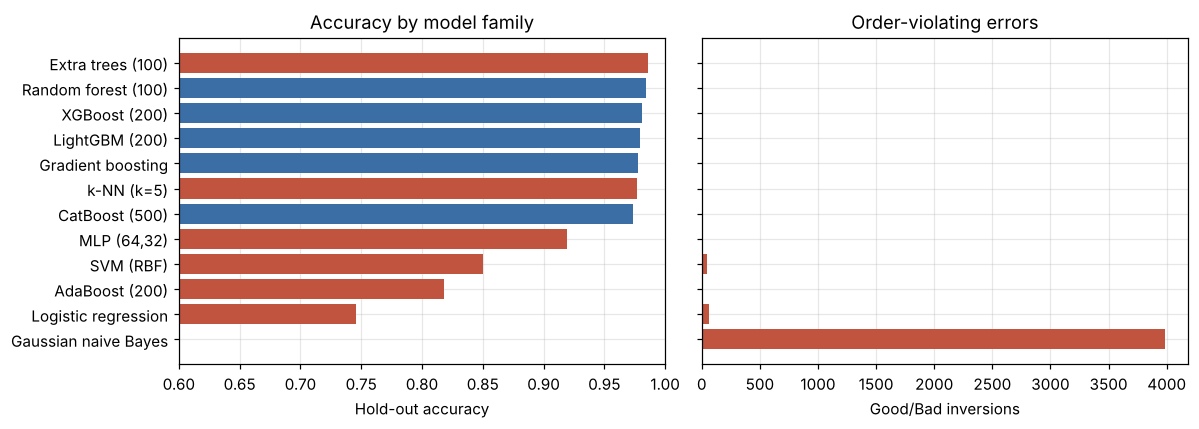

In [11]:
# 10a) Nine model families at default settings
if ENABLE_FAMILY_STUDY:
    try:
        import lightgbm as lgbm
    except ImportError:
        !pip install lightgbm -q
        import lightgbm as lgbm
    try:
        from catboost import CatBoostClassifier
    except ImportError:
        !pip install catboost -q
        from catboost import CatBoostClassifier
    from sklearn.ensemble import (HistGradientBoostingClassifier, ExtraTreesClassifier,
                                  AdaBoostClassifier)
    from sklearn.naive_bayes import GaussianNB
    from sklearn.neural_network import MLPClassifier
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.linear_model import LogisticRegression
    from sklearn.svm import SVC
    import time as _time

    FAMILIES = {
        "Random forest (100)":    RandomForestClassifier(n_estimators=100, n_jobs=-1,
                                                         random_state=MODEL_SEED),
        "XGBoost (200)":          X.XGBClassifier(objective="multi:softprob", num_class=NCLS,
                                                  n_estimators=200, tree_method="hist", n_jobs=-1,
                                                  random_state=MODEL_SEED, verbosity=0),
        "LightGBM (200)":         lgbm.LGBMClassifier(n_estimators=200, n_jobs=-1,
                                                      random_state=MODEL_SEED, verbose=-1),
        "Gradient boosting":      HistGradientBoostingClassifier(random_state=MODEL_SEED),
        "k-NN (k=5)":             KNeighborsClassifier(n_neighbors=5, algorithm="brute", n_jobs=-1),
        "CatBoost (500)":         CatBoostClassifier(iterations=500, random_seed=MODEL_SEED,
                                                     verbose=0, allow_writing_files=False),
        "MLP (64,32)":            MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300,
                                                early_stopping=True, n_iter_no_change=15,
                                                random_state=MODEL_SEED),
        "SVM (RBF)":              SVC(kernel="rbf", C=1.0, gamma="scale", cache_size=800,
                                      random_state=MODEL_SEED),
        "Logistic regression":    LogisticRegression(max_iter=2000, random_state=MODEL_SEED),
        "Extra trees (100)":      ExtraTreesClassifier(n_estimators=100, n_jobs=-1,
                                                       random_state=MODEL_SEED),
        "AdaBoost (200)":         AdaBoostClassifier(n_estimators=200, random_state=MODEL_SEED),
        "Gaussian naive Bayes":   GaussianNB(),
    }

    # Whether the fitted model can be emitted as static C arrays and truncated to a budget.
    EXPORTABLE = {"Random forest (100)": "arrays, no truncation",
                  "Extra trees (100)": "arrays, no truncation",
                  "XGBoost (200)": "arrays, truncatable",
                  "LightGBM (200)": "arrays, truncatable",
                  "CatBoost (500)": "arrays, truncatable",
                  "AdaBoost (200)": "arrays, truncatable",
                  "Gradient boosting": "no exporter in this work",
                  "k-NN (k=5)": "stores the training set",
                  "MLP (64,32)": "weights, float matmul",
                  "SVM (RBF)": "stores support vectors",
                  "Gaussian naive Bayes": "closed form, tiny",
                  "Logistic regression": "closed form, tiny"}

    fam_rows = []
    for name, mdl in FAMILIES.items():
        t0 = _time.time(); mdl.fit(Str, ytr); fit_s = _time.time() - t0
        t0 = _time.time(); pr = np.asarray(mdl.predict(Ste)).ravel().astype(int)
        pred_s = _time.time() - t0
        cm = confusion_matrix(yte, pr, labels=range(NCLS))
        fam_rows.append({"model": name,
                         "accuracy": accuracy_score(yte, pr),
                         "balanced_accuracy": balanced_accuracy_score(yte, pr),
                         "f1_macro": f1_score(yte, pr, average="macro"),
                         "cohen_kappa": cohen_kappa_score(yte, pr),
                         "fit_seconds": round(fit_s, 2),
                         "predict_ms_per_record": round(1000 * pred_s / len(yte), 4),
                         "inversions": int(cm[0, 2] + cm[2, 0]),
                         "deployment": EXPORTABLE.get(name, "")})
        print(f"  {name:<24} acc={fam_rows[-1]['accuracy']:.4f}  "
              f"inversions={fam_rows[-1]['inversions']}", flush=True)

    fam = pd.DataFrame(fam_rows).sort_values("accuracy", ascending=False).reset_index(drop=True)
    save_table(fam, "tbl_5_8_model_families",
               "Table 5.8 Model families on the test set, all at default settings")
    display(fam)

    fig, ax = plt.subplots(1, 2, figsize=(11, 4.0))
    g = fam.sort_values("accuracy")
    colours = ["#3b6ea5" if e == 0 else "#c1543f" for e in g["inversions"]]
    ax[0].barh(g["model"], g["accuracy"], color=colours)
    ax[0].set_xlim(0.6, 1.0); ax[0].set_xlabel("Hold-out accuracy")
    ax[0].set_title("Accuracy by model family")
    ax[1].barh(g["model"], g["inversions"], color=colours)
    ax[1].set_xlabel("Good/Bad inversions"); ax[1].set_title("Order-violating errors")
    ax[1].set_yticklabels([])
    save_fig(fig, "fig_5_13_model_families", "Figure 5.13 Accuracy and order-violating errors by family")
    RESULTS["model_families"] = fam_rows


## 10b) The untuned ensemble as the point of departure

Tuning is reported as an improvement over a reference, so the reference is measured first. The
library defaults are a depth of six and a rate of 0.30. Its accuracy is the target; its exported
footprint is what makes it a reference rather than a candidate.


In [12]:
# 10b) The library defaults, with the flash cost of that accuracy
def export_size_of(booster, rounds):
    tmp = os.path.join(OUT_DIR, "_probe")
    kb, nn, nt = export_c(booster.get_dump(dump_format="json"), rounds,
                          MN, MX, WT, compute_base(booster, Str[0]), tmp, NFEAT)
    shutil.rmtree(tmp, ignore_errors=True)
    return kb, nn, nt

base_rows = []
for R in (100, 200):
    m = X.XGBClassifier(objective="multi:softprob", num_class=NCLS, n_estimators=R,
                        tree_method="hist", n_jobs=-1, random_state=MODEL_SEED, verbosity=0)
    m.fit(Str, ytr); pr = m.predict(Ste)
    kb, nn, nt = export_size_of(m.get_booster(), R)
    base_rows.append({"configuration": "defaults, depth 6, rate 0.30", "rounds": R,
                      "accuracy": accuracy_score(yte, pr),
                      "f1_macro": f1_score(yte, pr, average="macro"),
                      "nodes": nn, "c_KiB": round(kb, 1)})
    print(base_rows[-1], flush=True)
defaults_tbl = pd.DataFrame(base_rows)
save_table(defaults_tbl, "tbl_5_9_defaults",
           "Table 5.9 The boosted ensemble at its library defaults")
RESULTS["defaults"] = base_rows
display(defaults_tbl)


{'configuration': 'defaults, depth 6, rate 0.30', 'rounds': 100, 'accuracy': 0.9788843721770552, 'f1_macro': 0.9788494990235014, 'nodes': 22614, 'c_KiB': 627.6}


{'configuration': 'defaults, depth 6, rate 0.30', 'rounds': 200, 'accuracy': 0.9808604336043361, 'f1_macro': 0.9808419104725653, 'nodes': 42610, 'c_KiB': 1197.2}


,configuration,rounds,accuracy,f1_macro,nodes,c_KiB
0,"defaults, depth 6, rate 0.30",100,0.978884,0.978849,22614,627.6
1,"defaults, depth 6, rate 0.30",200,0.980860,0.980842,42610,1197.2


## 11) Hyper-parameter search

Every grid point is scored by stratified `k`-fold cross-validation on the training partition
only, so the hold-out set stays untouched until the final evaluation.

In [13]:
# 11) Grid search with stratified cross-validation
keys = list(PARAM_GRID); combos = list(itertools.product(*[PARAM_GRID[k] for k in keys]))
skf = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=MODEL_SEED)
print(f"searching {len(combos)} configurations x {CV_FOLDS}-fold CV "
      f"(n_estimators={SEARCH_N_ESTIMATORS}) ...")

def make_clf(p, n_est):
    return X.XGBClassifier(objective="multi:softprob", num_class=NCLS, n_estimators=n_est,
                           tree_method="hist", n_jobs=-1, random_state=MODEL_SEED,
                           eval_metric="mlogloss", verbosity=0, **p)

rows, res = [], []
for combo in combos:
    p = dict(zip(keys, combo)); accs, f1s = [], []
    for tri, vai in skf.split(Str, ytr):
        clf = make_clf(p, SEARCH_N_ESTIMATORS); clf.fit(Str[tri], ytr[tri])
        pr = clf.predict(Str[vai])
        accs.append(accuracy_score(ytr[vai], pr))
        f1s.append(f1_score(ytr[vai], pr, average="macro"))
    res.append((p, float(np.mean(accs))))
    rows.append({**p, "cv_accuracy_mean": np.mean(accs), "cv_accuracy_std": np.std(accs),
                 "cv_f1_macro_mean": np.mean(f1s),
                 **{f"fold{i+1}": a for i, a in enumerate(accs)}})
    print("  " + " ".join(f"{k}={v}" for k, v in p.items()) +
          f" | CV acc={np.mean(accs):.4f} +/- {np.std(accs):.4f}")

cv_tbl = pd.DataFrame(rows).sort_values("cv_accuracy_mean", ascending=False).reset_index(drop=True)
save_table(cv_tbl, "tbl_5_10_cv_grid", f"Table 5.10 Fivefold cross-validation over the search space")
display(cv_tbl.head(10))

res.sort(key=lambda r: -r[1]); best_overall = res[0][0]
best_by_depth = {}
for p, a in res:
    d = p["max_depth"]
    if d not in best_by_depth or a > best_by_depth[d][1]: best_by_depth[d] = (p, a)
print("\n>>> best overall:", best_overall, "CV accuracy =", round(res[0][1], 4))
RESULTS["best_config"] = {"params": best_overall, "cv_accuracy": float(res[0][1])}

searching 18 configurations x 5-fold CV (n_estimators=250) ...


  max_depth=4 learning_rate=0.1 min_child_weight=1 reg_lambda=2.0 | CV acc=0.9591 +/- 0.0007


  max_depth=4 learning_rate=0.1 min_child_weight=5 reg_lambda=2.0 | CV acc=0.9584 +/- 0.0010


  max_depth=4 learning_rate=0.2 min_child_weight=1 reg_lambda=2.0 | CV acc=0.9738 +/- 0.0008


  max_depth=4 learning_rate=0.2 min_child_weight=5 reg_lambda=2.0 | CV acc=0.9732 +/- 0.0006


...

  max_depth=8 learning_rate=0.2 min_child_weight=5 reg_lambda=2.0 | CV acc=0.9807 +/- 0.0008


  max_depth=8 learning_rate=0.3 min_child_weight=1 reg_lambda=2.0 | CV acc=0.9806 +/- 0.0009


  max_depth=8 learning_rate=0.3 min_child_weight=5 reg_lambda=2.0 | CV acc=0.9803 +/- 0.0009


,max_depth,learning_rate,min_child_weight,reg_lambda,cv_accuracy_mean,cv_accuracy_std,cv_f1_macro_mean,fold1,fold2,fold3,fold4,fold5
0,8,0.2,1,2.0,0.980775,0.000814,0.980761,0.981793,0.979956,0.981509,0.979745,0.980874
1,8,0.2,5,2.0,0.980747,0.000843,0.980734,0.981299,0.980874,0.981438,0.979109,0.981015
2,8,0.3,1,2.0,0.980620,0.000947,0.980607,0.981793,0.980521,0.981438,0.979109,0.980239
3,8,0.3,5,2.0,0.980338,0.000911,0.980326,0.980875,0.979533,0.981156,0.978968,0.981156
4,6,0.3,1,2.0,0.980309,0.000944,0.980296,0.980452,0.979392,0.980239,0.979462,0.982003
5,6,0.2,1,2.0,0.979985,0.000952,0.979969,0.979605,0.979462,0.981085,0.978686,0.981085
6,6,0.3,5,2.0,0.979858,0.000799,0.979845,0.979323,0.979886,0.980944,0.978686,0.980450
7,8,0.1,1,2.0,0.979829,0.000686,0.979809,0.980240,0.980239,0.980239,0.978474,0.979956
8,6,0.2,5,2.0,0.979646,0.000616,0.979633,0.979323,0.978898,0.980380,0.979250,0.980380
9,8,0.1,5,2.0,0.978997,0.000573,0.978982,0.978687,0.979745,0.978968,0.978121,0.979462



>>> best overall: {'max_depth': 8, 'learning_rate': 0.2, 'min_child_weight': 1, 'reg_lambda': 2.0} CV accuracy = 0.9808


## 11a) One parameter at a time

Depth, learning rate and round count are swept separately so that the mechanism behind each is
separable. The depth sweep carries four columns that move in different directions: training
accuracy, hold-out accuracy, accuracy on a withheld clock band, and the size of the generated C.
Their disagreement is the finding, since depth beyond four buys in-distribution accuracy by
isolating repeated measurements of the same operating point and loses transfer to an unseen clock.


{'max_depth': 2, 'train_accuracy': 0.9012788301386105, 'hold_out_accuracy': 0.8964543812104788, 'withheld_band_mean': 0.834334430284407, 'nodes': 4188, 'c_KiB': 116.9}


{'max_depth': 3, 'train_accuracy': 0.9354656579058803, 'hold_out_accuracy': 0.934056007226739, 'withheld_band_mean': 0.8339610771819134, 'nodes': 8706, 'c_KiB': 239.5}


{'max_depth': 4, 'train_accuracy': 0.9576122858030094, 'hold_out_accuracy': 0.9546070460704607, 'withheld_band_mean': 0.8113268269929741, 'nodes': 16040, 'c_KiB': 446.4}


{'max_depth': 5, 'train_accuracy': 0.9742399006295345, 'hold_out_accuracy': 0.9676490514905149, 'withheld_band_mean': 0.7956588215054957, 'nodes': 28200, 'c_KiB': 791.3}


{'max_depth': 6, 'train_accuracy': 0.9840922564435536, 'hold_out_accuracy': 0.9758355916892503, 'withheld_band_mean': 0.7863807101306652, 'nodes': 45468, 'c_KiB': 1282.0}


{'max_depth': 8, 'train_accuracy': 0.9930835897580668, 'hold_out_accuracy': 0.9800700090334237, 'withheld_band_mean': 0.7839374099786085, 'nodes': 96154, 'c_KiB': 2730.5}


,max_depth,train_accuracy,hold_out_accuracy,withheld_band_mean,nodes,c_KiB
0,2,0.901279,0.896454,0.834334,4188,116.9
1,3,0.935466,0.934056,0.833961,8706,239.5
2,4,0.957612,0.954607,0.811327,16040,446.4
3,5,0.974240,0.967649,0.795659,28200,791.3
4,6,0.984092,0.975836,0.786381,45468,1282.0
5,8,0.993084,0.980070,0.783937,96154,2730.5


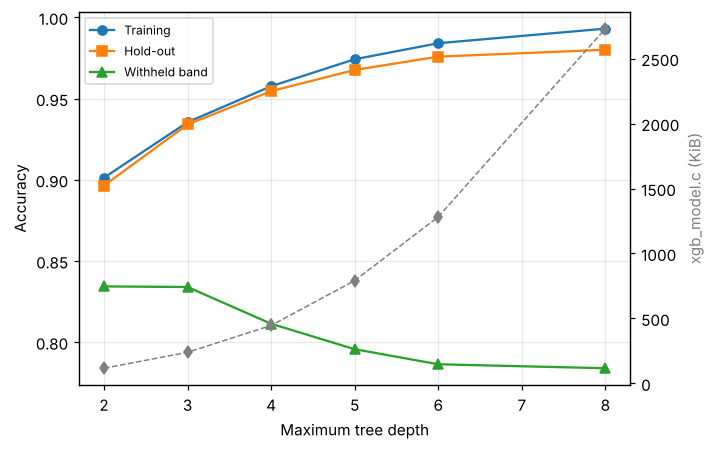

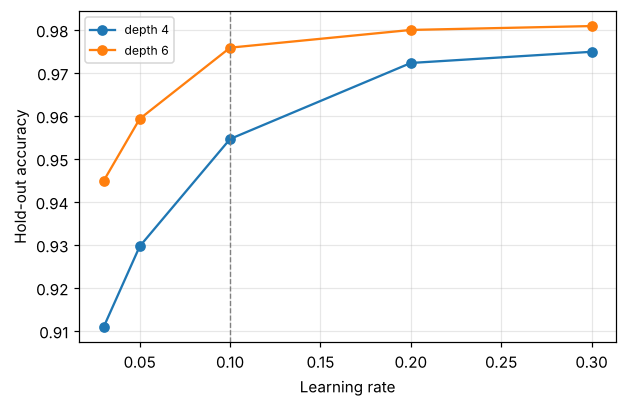

In [14]:
# 11a) Depth, learning-rate and round sweeps
if ENABLE_SWEEPS:
    def lobo_mean(params, n_est):
        accs = []
        for b in sorted(set(df["band"])):
            msk = (df["band"] == b).to_numpy()
            if msk.sum() < 50 or len(np.unique(yy[msk])) < 2: continue
            mdl = make_clf(params, n_est)
            mdl.fit(apply_scaler(Xdf[~msk], MN, MX, WT), yy[~msk])
            accs.append(accuracy_score(yy[msk], mdl.predict(apply_scaler(Xdf[msk], MN, MX, WT))))
        return float(np.mean(accs)) if accs else np.nan

    depth_rows = []
    for depth in [2, 3, 4, 5, 6, 8]:
        p = {"max_depth": depth, "learning_rate": 0.1}
        m = make_clf(p, 200); m.fit(Str, ytr)
        kb, nn, nt = export_size_of(m.get_booster(), 200)
        depth_rows.append({"max_depth": depth,
                           "train_accuracy": accuracy_score(ytr, m.predict(Str)),
                           "hold_out_accuracy": accuracy_score(yte, m.predict(Ste)),
                           "withheld_band_mean": lobo_mean(p, 200),
                           "nodes": nn, "c_KiB": round(kb, 1)})
        print(depth_rows[-1], flush=True)
    depth_tbl = pd.DataFrame(depth_rows)
    save_table(depth_tbl, "tbl_5_11_depth_sweep",
               "Table 5.11 Depth sweep at a learning rate of 0.10 and two hundred rounds")
    display(depth_tbl)

    fig, ax = plt.subplots(figsize=(6.6, 4.2))
    ax.plot(depth_tbl["max_depth"], depth_tbl["train_accuracy"], "o-", label="Training")
    ax.plot(depth_tbl["max_depth"], depth_tbl["hold_out_accuracy"], "s-", label="Hold-out")
    ax.plot(depth_tbl["max_depth"], depth_tbl["withheld_band_mean"], "^-", label="Withheld band")
    ax.set_xlabel("Maximum tree depth"); ax.set_ylabel("Accuracy"); ax.legend(fontsize=8)
    ax2 = ax.twinx(); ax2.grid(False)
    ax2.plot(depth_tbl["max_depth"], depth_tbl["c_KiB"], "d--", color="grey", lw=1)
    ax2.set_ylabel("xgb_model.c (KiB)", color="grey")
    save_fig(fig, "fig_5_14_depth_sweep",
             "Figure 5.14 Depth raises in-distribution accuracy and lowers transfer")

    lr_rows = []
    for lr in [0.03, 0.05, 0.1, 0.2, 0.3]:
        for depth in [4, 6]:
            m = make_clf({"max_depth": depth, "learning_rate": lr}, 200); m.fit(Str, ytr)
            pr = m.predict(Ste)
            lr_rows.append({"max_depth": depth, "learning_rate": lr,
                            "hold_out_accuracy": accuracy_score(yte, pr),
                            "f1_macro": f1_score(yte, pr, average="macro")})
    lr_tbl = pd.DataFrame(lr_rows)
    save_table(lr_tbl, "tbl_5_12_learning_rate", "Table 5.12 Learning rate at two hundred rounds")
    fig, ax = plt.subplots(figsize=(5.8, 3.8))
    for depth, g in lr_tbl.groupby("max_depth"):
        ax.plot(g["learning_rate"], g["hold_out_accuracy"], "o-", label=f"depth {depth}")
    ax.axvline(0.1, ls="--", lw=0.9, color="grey")
    ax.set_xlabel("Learning rate"); ax.set_ylabel("Hold-out accuracy"); ax.legend(fontsize=8)
    save_fig(fig, "fig_5_15_learning_rate", "Figure 5.15 Learning rate at fixed depth and rounds")
    RESULTS["sweeps"] = {"depth": depth_rows, "learning_rate": lr_rows}


## 12) Final model and evaluation stage

The winning configuration is refitted on the whole training partition. Two confusion matrices
are produced: one from out-of-fold cross-validation predictions, which describes stability
across folds, and one from the untouched hold-out partition, which is the figure quoted as the
generalisation result.

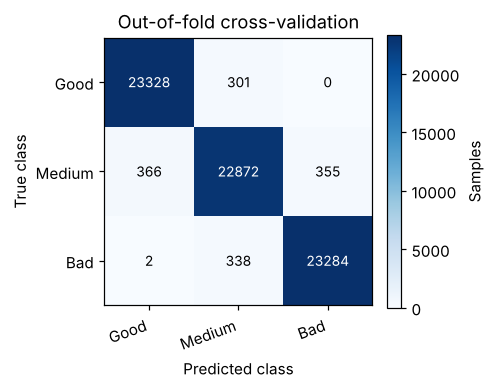

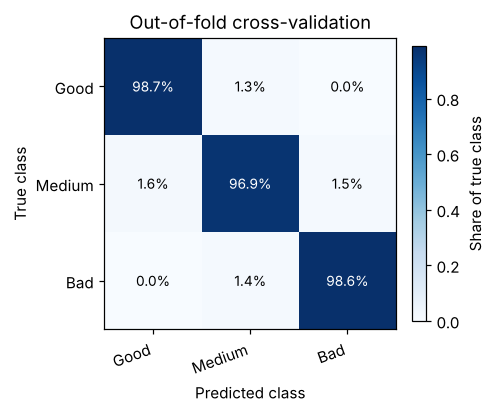

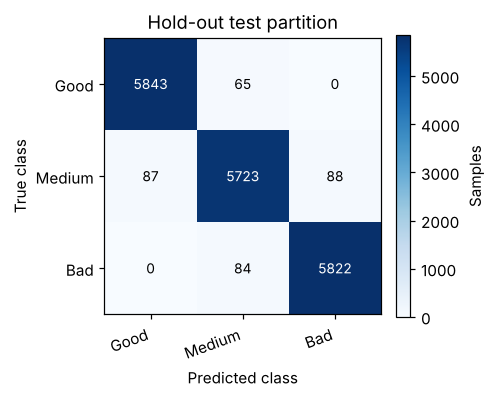

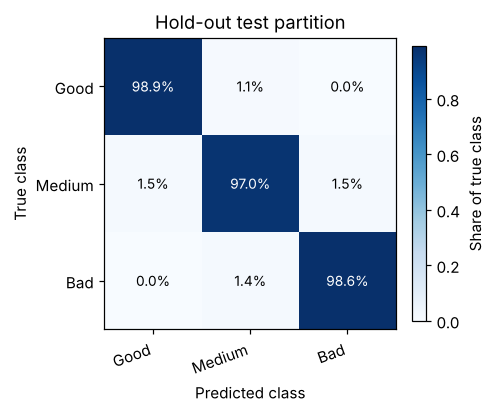

,class,precision,recall,f1_score,support
0,Good,0.985329,0.988998,0.987160,5908.000000
1,Medium,0.974625,0.970329,0.972472,5898.000000
2,Bad,0.985110,0.985777,0.985443,5906.000000
3,accuracy,0.981707,0.981707,0.981707,0.981707
4,macro avg,0.981688,0.981701,0.981692,17712.000000
5,weighted avg,0.981692,0.981707,0.981697,17712.000000


,stage,accuracy,balanced_accuracy,f1_macro,f1_weighted,cohen_kappa,mcc,log_loss
0,cross-validation (out-of-fold),0.980775,0.980770,0.980762,0.980767,0.971163,0.971164,NaN
1,hold-out test,0.981707,0.981701,0.981692,0.981697,0.972561,0.972564,0.047081


In [15]:
# 12) Final model, cross-validated and hold-out evaluation
FINAL_ROUNDS = SEARCH_N_ESTIMATORS
final = make_clf(best_overall, FINAL_ROUNDS)

oof = cross_val_predict(make_clf(best_overall, FINAL_ROUNDS), Str, ytr, cv=skf, n_jobs=1)
cm_cv = confusion_matrix(ytr, oof, labels=range(NCLS))
m_cv = metric_block(ytr, oof, tag="cross_validation")
plot_confusion(cm_cv, "Out-of-fold cross-validation", "fig_5_2_confusion_cv_counts",
               "Figure 5.2 Confusion matrix, out-of-fold cross-validation (counts)")
plot_confusion(cm_cv, "Out-of-fold cross-validation", "fig_5_3_confusion_cv_norm",
               "Figure 5.3 Confusion matrix, out-of-fold cross-validation (row-normalised)",
               normalise=True)

final.fit(Str, ytr)
proba = final.predict_proba(Ste); pred = proba.argmax(1)
cm_te = confusion_matrix(yte, pred, labels=range(NCLS))
m_te = metric_block(yte, pred, proba, tag="hold_out_test")
plot_confusion(cm_te, "Hold-out test partition", "fig_5_4_confusion_test_counts",
               "Figure 5.4 Confusion matrix, hold-out test partition (counts)")
plot_confusion(cm_te, "Hold-out test partition", "fig_5_5_confusion_test_norm",
               "Figure 5.5 Confusion matrix, hold-out test partition (row-normalised)",
               normalise=True)

save_table(pd.DataFrame(cm_te, index=[f"true {c}" for c in CLASS_NAMES],
                        columns=[f"pred {c}" for c in CLASS_NAMES]).reset_index(),
           "tbl_5_13_confusion_test", "Table 5.13 Confusion matrix on the test set", index=False)
save_table(pd.DataFrame(cm_cv, index=[f"true {c}" for c in CLASS_NAMES],
                        columns=[f"pred {c}" for c in CLASS_NAMES]).reset_index(),
           "tbl_5_14_confusion_cv", "Table 5.14 Confusion matrix from out-of-fold cross-validation", index=False)

rep = pd.DataFrame(classification_report(yte, pred, target_names=CLASS_NAMES,
                                         output_dict=True, zero_division=0)).T.reset_index()
rep.columns = ["class", "precision", "recall", "f1_score", "support"]
save_table(rep, "tbl_5_15_classification_report",
           "Table 5.15 Per class precision, recall and F1 on the test set")
display(rep)

summ = pd.DataFrame([{"stage": "cross-validation (out-of-fold)", **m_cv},
                     {"stage": "hold-out test", **m_te}])
save_table(summ, "tbl_5_16_headline_metrics", "Table 5.16 Headline metrics for the selected configuration")
display(summ)

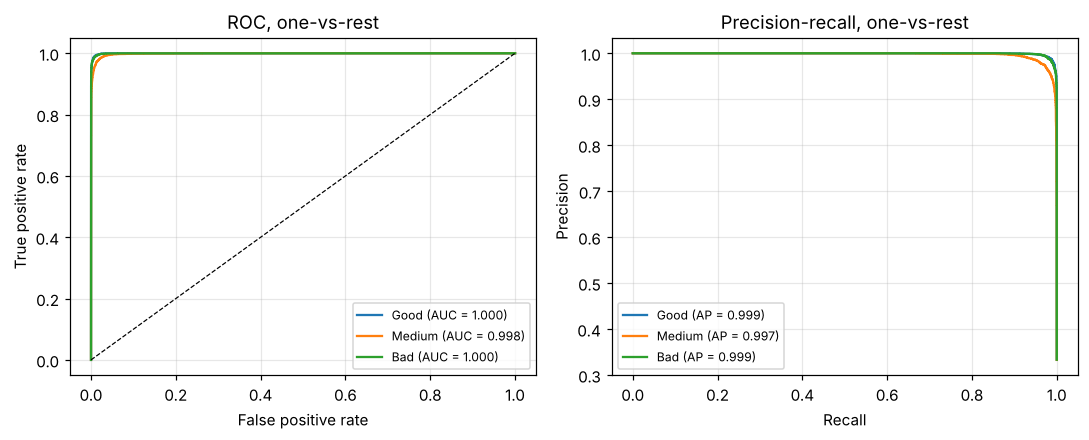

In [16]:
# 13) ROC and precision-recall behaviour (one-vs-rest)
Yb = label_binarize(yte, classes=range(NCLS))
fig, ax = plt.subplots(1, 2, figsize=(10, 4.1))
auc_rows = []
for i, name in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(Yb[:, i], proba[:, i]); a = auc(fpr, tpr)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC = {a:.3f})")
    pr_, rc_, _ = precision_recall_curve(Yb[:, i], proba[:, i])
    ap = average_precision_score(Yb[:, i], proba[:, i])
    ax[1].plot(rc_, pr_, label=f"{name} (AP = {ap:.3f})")
    auc_rows.append({"class": name, "roc_auc": a, "average_precision": ap})
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
ax[0].set_title("ROC, one-vs-rest"); ax[0].legend(fontsize=8, loc="lower right")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
ax[1].set_title("Precision-recall, one-vs-rest"); ax[1].legend(fontsize=8, loc="lower left")
save_fig(fig, "fig_5_6_roc_pr", "Figure 5.6 ROC and precision-recall curves on the hold-out partition")
auc_tbl = pd.DataFrame(auc_rows)
save_table(auc_tbl, "tbl_5_17_auc", "Table 5.17 Area under ROC and average precision per tier")
RESULTS["auc"] = auc_tbl.set_index("class").to_dict()

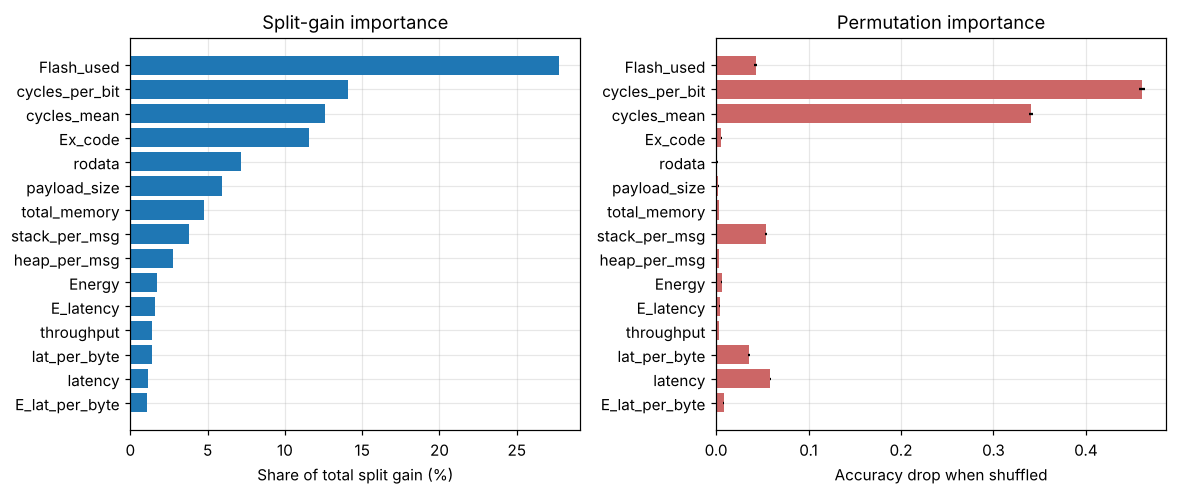

In [17]:
# 14) Feature importance
gain = final.get_booster().get_score(importance_type="gain")
gi = pd.DataFrame({"feature": COLS,
                   "gain": [gain.get(f"f{i}", 0.0) for i in range(len(COLS))]})
gi["gain_share_%"] = 100 * gi["gain"] / max(gi["gain"].sum(), 1e-12)
gi = gi.sort_values("gain", ascending=False).reset_index(drop=True)

if ENABLE_PERMUTATION:
    pi = permutation_importance(final, Ste, yte, n_repeats=5,
                                random_state=MODEL_SEED, scoring="accuracy", n_jobs=1)
    gi = gi.merge(pd.DataFrame({"feature": COLS,
                                "perm_importance_mean": pi.importances_mean,
                                "perm_importance_std": pi.importances_std}), on="feature")
save_table(gi, "tbl_5_18_feature_importance",
           "Table 5.18 Feature importance by split gain and by permutation")

top = gi.head(15).iloc[::-1]
ncol = 2 if ENABLE_PERMUTATION else 1
fig, ax = plt.subplots(1, ncol, figsize=(5.4 * ncol, 4.6))
ax = np.atleast_1d(ax)
ax[0].barh(top["feature"], top["gain_share_%"])
ax[0].set_xlabel("Share of total split gain (%)"); ax[0].set_title("Split-gain importance")
if ENABLE_PERMUTATION:
    ax[1].barh(top["feature"], top["perm_importance_mean"],
               xerr=top["perm_importance_std"], color="#c66")
    ax[1].set_xlabel("Accuracy drop when shuffled"); ax[1].set_title("Permutation importance")
save_fig(fig, "fig_5_7_feature_importance", "Figure 5.7 Feature importance of the runtime classifier")

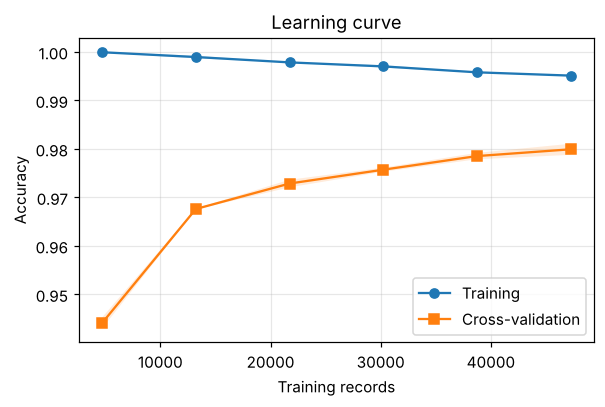

In [18]:
# 15) Learning curve
if ENABLE_LEARNING_CURVE:
    sizes = np.linspace(0.1, 1.0, 6)
    ts, tr_sc, va_sc = learning_curve(
        make_clf(best_overall, max(60, FINAL_ROUNDS // 2)), Str, ytr,
        train_sizes=sizes, cv=3, scoring="accuracy", n_jobs=1, shuffle=True,
        random_state=MODEL_SEED)
    lc = pd.DataFrame({"train_size": ts,
                       "train_accuracy_mean": tr_sc.mean(1), "train_accuracy_std": tr_sc.std(1),
                       "cv_accuracy_mean": va_sc.mean(1), "cv_accuracy_std": va_sc.std(1)})
    save_table(lc, "tbl_5_19_learning_curve", "Table 5.19 Learning curve of the selected configuration")
    fig, ax = plt.subplots(figsize=(5.6, 3.8))
    ax.plot(ts, tr_sc.mean(1), "o-", label="Training")
    ax.fill_between(ts, tr_sc.mean(1)-tr_sc.std(1), tr_sc.mean(1)+tr_sc.std(1), alpha=0.15)
    ax.plot(ts, va_sc.mean(1), "s-", label="Cross-validation")
    ax.fill_between(ts, va_sc.mean(1)-va_sc.std(1), va_sc.mean(1)+va_sc.std(1), alpha=0.15)
    ax.set_xlabel("Training records"); ax.set_ylabel("Accuracy"); ax.legend()
    ax.set_title("Learning curve")
    save_fig(fig, "fig_5_8_learning_curve", "Figure 5.8 Learning curve of the runtime classifier")

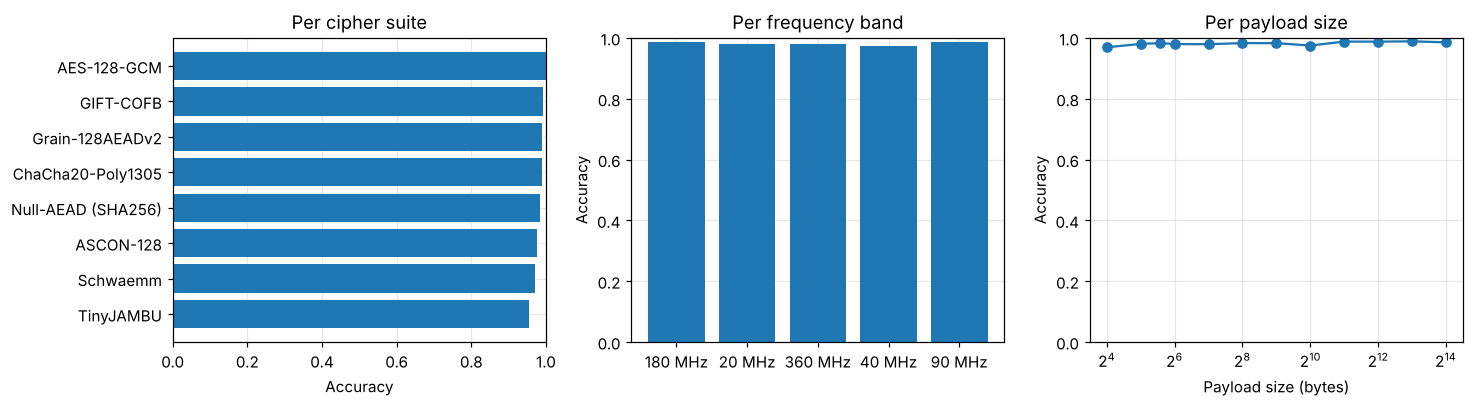

,cipher,accuracy,records
0,TinyJAMBU,0.953318,2185
1,Schwaemm,0.971863,2168
2,ASCON-128,0.976543,2771
3,Null-AEAD (SHA256),0.983577,2192
4,ChaCha20-Poly1305,0.989733,2435
5,Grain-128AEADv2,0.989834,1869
6,GIFT-COFB,0.992495,2132
7,AES-128-GCM,1.000000,1960


In [19]:
# 16) Error analysis across ciphers, payloads and bands
err = meta_te.copy(); err["true"] = le.inverse_transform(yte); err["pred"] = le.inverse_transform(pred)
err["correct"] = err["true"] == err["pred"]

by_cipher = (err.groupby("cipher")["correct"].agg(["mean", "count"])
               .rename(columns={"mean": "accuracy", "count": "records"})
               .sort_values("accuracy").reset_index())
by_band = (err.groupby("band")["correct"].agg(["mean", "count"])
             .rename(columns={"mean": "accuracy", "count": "records"}).reset_index())
by_pay = (err.groupby("payload_size")["correct"].agg(["mean", "count"])
            .rename(columns={"mean": "accuracy", "count": "records"}).reset_index())
save_table(by_cipher, "tbl_5_20_accuracy_by_cipher", "Table 5.20 Test-set accuracy per cipher suite")
save_table(by_band, "tbl_5_21_accuracy_by_band", "Table 5.21 Test-set accuracy per clock band")
save_table(by_pay, "tbl_5_22_accuracy_by_payload", "Table 5.22 Test-set accuracy per payload size")

fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.8))
ax[0].barh(by_cipher["cipher"], by_cipher["accuracy"]); ax[0].set_xlim(0, 1)
ax[0].set_xlabel("Accuracy"); ax[0].set_title("Per cipher suite")
ax[1].bar(by_band["band"], by_band["accuracy"]); ax[1].set_ylim(0, 1)
ax[1].set_ylabel("Accuracy"); ax[1].set_title("Per frequency band")
ax[2].plot(by_pay["payload_size"], by_pay["accuracy"], "o-")
ax[2].set_xscale("log", base=2); ax[2].set_ylim(0, 1)
ax[2].set_xlabel("Payload size (bytes)"); ax[2].set_ylabel("Accuracy")
ax[2].set_title("Per payload size")
save_fig(fig, "fig_5_9_error_analysis", "Figure 5.9 Hold-out accuracy by cipher, band and payload")
display(by_cipher)

## 17) Cross-band generalisation

Each frequency band is withheld in turn, the model is refitted on the remaining bands and
scored on the unseen one. This measures whether the classifier transfers to a clock setting
it has never observed, which is the situation created by dynamic frequency scaling on the node.
A band that carries only one cipher suite cannot be ranked against alternatives, so its score
falls back towards the 1/3 chance level; read Table 5.2 before interpreting Table 5.19.

,held_out_band,train_records,test_records,accuracy,balanced_accuracy,f1_macro
0,20 MHz,71728,16830,0.655377,0.655278,0.639653
1,40 MHz,71511,17047,0.880565,0.880511,0.879928
2,90 MHz,67118,21440,0.820756,0.820741,0.819176
3,180 MHz,72204,16354,0.831723,0.831661,0.830742
4,360 MHz,71671,16887,0.694321,0.694084,0.675398


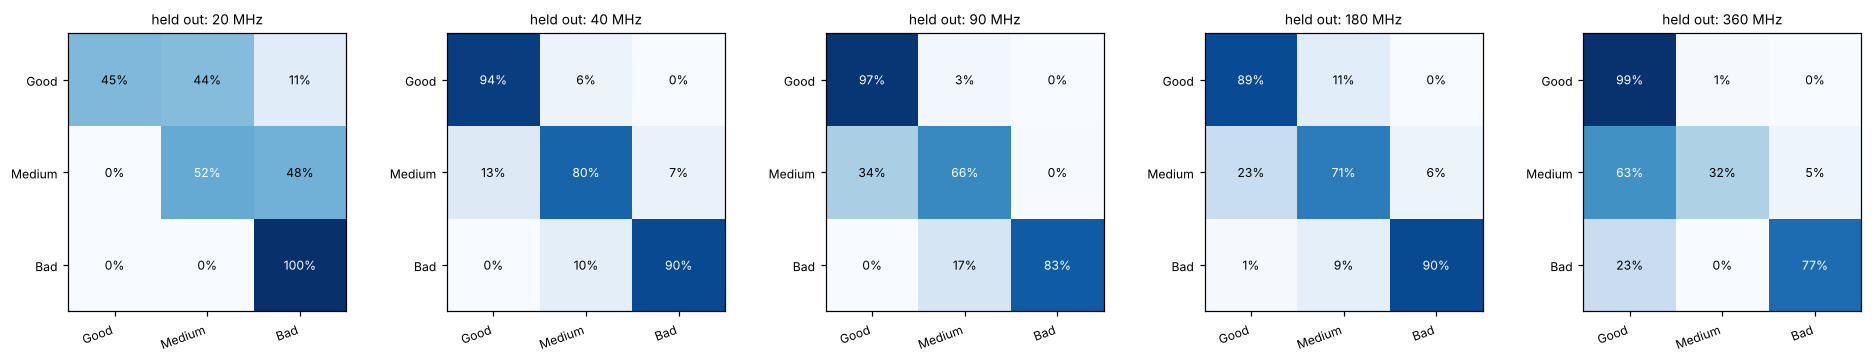

In [20]:
# 17) Leave-one-band-out study
if ENABLE_LOBO and df["band"].nunique() > 1:
    bands = [b for b in DATASETS if b in set(df["band"])]
    lobo_rows, cms = [], {}
    for b in bands:
        m = (df["band"] == b).to_numpy()
        if m.sum() < 50 or (~m).sum() < 200: continue
        A = apply_scaler(Xdf[~m], MN, MX, WT); B = apply_scaler(Xdf[m], MN, MX, WT)
        ya, yb = yy[~m], yy[m]
        if len(np.unique(yb)) < 2: continue
        mdl = make_clf(best_overall, FINAL_ROUNDS); mdl.fit(A, ya)
        pb = mdl.predict(B)
        lobo_rows.append({"held_out_band": b, "train_records": int((~m).sum()),
                          "test_records": int(m.sum()),
                          "accuracy": accuracy_score(yb, pb),
                          "balanced_accuracy": balanced_accuracy_score(yb, pb),
                          "f1_macro": f1_score(yb, pb, average="macro")})
        cms[b] = confusion_matrix(yb, pb, labels=range(NCLS))
    if lobo_rows:
        lobo = pd.DataFrame(lobo_rows)
        save_table(lobo, "tbl_5_23_cross_band",
                   "Table 5.23 Leave one band out generalisation")
        display(lobo)
        n = len(cms)
        fig, ax = plt.subplots(1, n, figsize=(3.5 * n, 3.4))
        ax = np.atleast_1d(ax)
        for k, (b, cm) in enumerate(cms.items()):
            M = cm / np.maximum(cm.sum(1, keepdims=True), 1)
            ax[k].imshow(M, cmap="Blues", vmin=0, vmax=1); ax[k].grid(False)
            ax[k].set_xticks(range(NCLS), CLASS_NAMES, rotation=20, ha="right", fontsize=8)
            ax[k].set_yticks(range(NCLS), CLASS_NAMES, fontsize=8)
            ax[k].set_title(f"held out: {b}", fontsize=9)
            for i in range(NCLS):
                for j in range(NCLS):
                    ax[k].text(j, i, "{:.0%}".format(M[i, j]), ha="center", va="center",
                               fontsize=8, color="white" if M[i, j] > 0.5 else "black")
        save_fig(fig, "fig_5_10_cross_band",
                 "Figure 5.10 Row-normalised confusion matrices for each withheld band")
        RESULTS["cross_band"] = lobo.to_dict(orient="records")

In [21]:
# 17b) Feature-set ablation: what does the model really need?
STATIC_MEM = ["Flash_used", "Ex_code", "rodata", "total_memory"]
DYN_MEM    = ["heap_per_msg", "stack_per_msg"]
# C keeps only quantities that measure time or work; both memory groups are removed.
TIMING_ONLY = ["latency", "E_latency", "lat_per_byte", "E_lat_per_byte", "cv_latency",
               "lat_per_byte_std", "E_lat_per_byte_std", "throughput", "cycles_mean",
               "cycles_per_bit", "Energy", "payload_size"]
CLOCK_INV  = ["cycles_per_bit", "cycles_mean", "Energy", "payload_size",
              "heap_per_msg", "stack_per_msg", "cv_latency"]
SETS = {
    "A all features": FEATS,
    "B without build constants": [c for c in FEATS if c not in STATIC_MEM],
    "C timing only": [c for c in TIMING_ONLY if c in FEATS],
    "D clock-invariant work": [c for c in CLOCK_INV if c in FEATS],
}
for _n, _c in SETS.items():
    print(f"  {_n}: {len(_c)} features")
ab_rows = []
for name, cols in SETS.items():
    A = Xdf[cols]
    _, mn2, mx2, wt2 = fit_scaler(A.iloc[itr])
    m = make_clf(best_overall, FINAL_ROUNDS)
    m.fit(apply_scaler(A.iloc[itr], mn2, mx2, wt2), ytr)
    pr = m.predict(apply_scaler(A.iloc[ite], mn2, mx2, wt2))
    row = {"feature_set": name, "n_features": len(cols),
           "hold_out_accuracy": accuracy_score(yte, pr),
           "f1_macro": f1_score(yte, pr, average="macro")}
    lo = []
    if ENABLE_LOBO:
        for b in sorted(set(df["band"])):
            msk = (df["band"] == b).to_numpy()
            if msk.sum() < 50 or len(np.unique(yy[msk])) < 2: continue
            _, mn3, mx3, wt3 = fit_scaler(A[~msk])
            mm = make_clf(best_overall, FINAL_ROUNDS)
            mm.fit(apply_scaler(A[~msk], mn3, mx3, wt3), yy[~msk])
            a = accuracy_score(yy[msk], mm.predict(apply_scaler(A[msk], mn3, mx3, wt3)))
            row["LOBO_" + b.replace(" ", "")] = a; lo.append(a)
        row["LOBO_mean"] = float(np.mean(lo)) if lo else np.nan
    ab_rows.append(row); print(row, flush=True)
ablation = pd.DataFrame(ab_rows)
save_table(ablation, "tbl_5_24_ablation",
           "Table 5.24 Feature subsets, with mean band-withholding accuracy")
display(ablation)
RESULTS["ablation"] = ablation.to_dict(orient="records")

  A all features: 18 features
  B without build constants: 14 features
  C timing only: 12 features
  D clock-invariant work: 7 features


{'feature_set': 'A all features', 'n_features': 18, 'hold_out_accuracy': 0.9817073170731707, 'f1_macro': 0.9816919490512935, 'LOBO_180MHz': 0.8307447719212425, 'LOBO_20MHz': 0.6409387997623291, 'LOBO_360MHz': 0.6557707111979629, 'LOBO_40MHz': 0.8722942453217575, 'LOBO_90MHz': 0.8159514925373135, 'LOBO_mean': 0.7631400041481211}


{'feature_set': 'B without build constants', 'n_features': 14, 'hold_out_accuracy': 0.9802393857271906, 'f1_macro': 0.980217967056296, 'LOBO_180MHz': 0.8267702091231502, 'LOBO_20MHz': 0.6387997623291741, 'LOBO_360MHz': 0.6891099662462249, 'LOBO_40MHz': 0.858684812576993, 'LOBO_90MHz': 0.8182369402985075, 'LOBO_mean': 0.7663203381148099}


{'feature_set': 'C timing only', 'n_features': 12, 'hold_out_accuracy': 0.9677055103884372, 'f1_macro': 0.9676720045440187, 'LOBO_180MHz': 0.8394888100770453, 'LOBO_20MHz': 0.638680926916221, 'LOBO_360MHz': 0.7739089240243975, 'LOBO_40MHz': 0.858684812576993, 'LOBO_90MHz': 0.8032182835820896, 'LOBO_mean': 0.7827963514353493}


{'feature_set': 'D clock-invariant work', 'n_features': 7, 'hold_out_accuracy': 0.9533649503161699, 'f1_macro': 0.9532204938186046, 'LOBO_180MHz': 0.8371040723981901, 'LOBO_20MHz': 0.8234105763517529, 'LOBO_360MHz': 0.7790608160123171, 'LOBO_40MHz': 0.8626151228955241, 'LOBO_90MHz': 0.8316231343283582, 'LOBO_mean': 0.8267627443972284}


,feature_set,n_features,hold_out_accuracy,f1_macro,LOBO_180MHz,LOBO_20MHz,LOBO_360MHz,LOBO_40MHz,LOBO_90MHz,LOBO_mean
0,A all features,18,0.981707,0.981692,0.830745,0.640939,0.655771,0.872294,0.815951,0.763140
1,B without build constants,14,0.980239,0.980218,0.826770,0.638800,0.689110,0.858685,0.818237,0.766320
2,C timing only,12,0.967706,0.967672,0.839489,0.638681,0.773909,0.858685,0.803218,0.782796
3,D clock-invariant work,7,0.953365,0.953220,0.837104,0.823411,0.779061,0.862615,0.831623,0.826763


## 17c) Priority-profile sensitivity

The weights define the target, so they must be varied before any importance ranking is quoted.
Each profile is relabelled from scratch, a model is trained under identical settings, and the
permutation importance is recomputed. Accuracy that barely moves across profiles is a sign that
the model recovers whatever composite it is given, not that the weighting is right.

In [22]:
# 17c) Train under alternative priority vectors
P_LAT = {"latency": (3.0, +1), "E_latency": (3.0, +1), "cycles_per_bit": (3.0, +1),
         "lat_per_byte": (2.5, +1), "E_lat_per_byte": (2.5, +1), "throughput": (2.0, -1),
         "cycles_mean": (1.5, +1), "Energy": (1.0, +1), "cpu_freq_mhz": (2.0, -1),
         "payload_size": (1.0, +1), "stack_per_msg": (0.5, +1), "heap_per_msg": (0.3, +1),
         "Flash_used": (0.3, +1), "Ex_code": (0.3, +1), "rodata": (0.3, +1),
         "total_memory": (0.3, +1), "cv_latency": (0.5, +1),
         "lat_per_byte_std": (0.3, +1), "E_lat_per_byte_std": (0.3, +1)}
P_FOOT = {"Flash_used": (3.0, +1), "Ex_code": (3.0, +1), "total_memory": (3.0, +1),
          "rodata": (2.0, +1), "stack_per_msg": (2.5, +1), "heap_per_msg": (2.5, +1),
          "Energy": (2.0, +1), "cycles_per_bit": (1.5, +1), "latency": (1.0, +1),
          "E_latency": (1.0, +1), "throughput": (1.0, -1), "cycles_mean": (1.0, +1),
          "lat_per_byte": (0.5, +1), "E_lat_per_byte": (0.5, +1), "cpu_freq_mhz": (1.0, -1),
          "payload_size": (1.0, +1), "cv_latency": (0.3, +1),
          "lat_per_byte_std": (0.3, +1), "E_lat_per_byte_std": (0.3, +1)}
PROFILES = {"P0 baseline": FEATURE_PRIORITY, "P1 latency-led": P_LAT,
            "P2 footprint-led": P_FOOT,
            "P3 uniform": {k: (1.0, v[1]) for k, v in FEATURE_PRIORITY.items()}}

def labels_with(prof):
    lab = pd.Series("", index=df.index)
    for _, ix in df.groupby(["band", "payload_size"]).groups.items():
        s = pd.Series(0.0, index=ix)
        for c, (w, sg) in prof.items():
            if c in df.columns: s = s + sg * w * minmax(df.loc[ix, c]).fillna(0.0)
        try: t = pd.qcut(s, 3, labels=CLASS_NAMES, duplicates="drop").astype(str)
        except ValueError: t = pd.qcut(s.rank(method="first"), 3, labels=CLASS_NAMES).astype(str)
        lab.loc[ix] = t.values
    return lab

prof_rows, prof_imp = [], []
LAB = {n: labels_with(p) for n, p in PROFILES.items()}
for name, prof in PROFILES.items():
    yv = le.transform(LAB[name])
    a, b = train_test_split(np.arange(len(df)), test_size=TEST_SIZE,
                            random_state=SPLIT_SEED, stratify=yv)
    A, B = Xdf.iloc[a], Xdf.iloc[b]
    cols2, mn2, mx2, _ = fit_scaler(A)
    wtp = np.array([prof.get(c, (DEFAULT_WEIGHT, 1))[0] for c in cols2], np.float32)
    m = make_clf(best_overall, FINAL_ROUNDS)
    m.fit(apply_scaler(A, mn2, mx2, wtp), yv[a])
    pr = m.predict(apply_scaler(B, mn2, mx2, wtp))
    m2 = make_clf(best_overall, FINAL_ROUNDS)      # weights removed from the scaler
    one = np.ones_like(wtp)
    m2.fit(apply_scaler(A, mn2, mx2, one), yv[a])
    pr2 = m2.predict(apply_scaler(B, mn2, mx2, one))
    pi2 = permutation_importance(m, apply_scaler(B, mn2, mx2, wtp), yv[b], n_repeats=3,
                                 random_state=MODEL_SEED, scoring="accuracy", n_jobs=1)
    top = np.argsort(-pi2.importances_mean)[:3]
    prof_rows.append({"profile": name,
                      "agreement_with_P0": float((LAB[name] == LAB["P0 baseline"]).mean()),
                      "accuracy_weighted_scaling": accuracy_score(yv[b], pr),
                      "accuracy_plain_scaling": accuracy_score(yv[b], pr2),
                      "top_drivers": ", ".join(cols2[i] for i in top)})
    for i in np.argsort(-pi2.importances_mean)[:8]:
        prof_imp.append({"profile": name, "feature": cols2[i],
                         "perm_importance": float(pi2.importances_mean[i])})
    print(prof_rows[-1], flush=True)

prof_tbl = pd.DataFrame(prof_rows)
save_table(prof_tbl, "tbl_5_25_priority_profiles",
           "Table 5.25 Classifier behaviour under alternative priority weights")
save_table(pd.DataFrame(prof_imp).pivot_table(index="feature", columns="profile",
           values="perm_importance").fillna(0).reset_index(),
           "tbl_5_26_importance_by_profile",
           "Table 5.26 Permutation importance under each set of priority weights", index=False)
display(prof_tbl)
RESULTS["priority_profiles"] = prof_rows

{'profile': 'P0 baseline', 'agreement_with_P0': 1.0, 'accuracy_weighted_scaling': 0.9817073170731707, 'accuracy_plain_scaling': 0.9817073170731707, 'top_drivers': 'cycles_per_bit, cycles_mean, latency'}


{'profile': 'P1 latency-led', 'agreement_with_P0': 0.9543124280132794, 'accuracy_weighted_scaling': 0.9840221318879856, 'accuracy_plain_scaling': 0.9840221318879856, 'top_drivers': 'cycles_per_bit, cycles_mean, latency'}


{'profile': 'P2 footprint-led', 'agreement_with_P0': 0.41546782899342805, 'accuracy_weighted_scaling': 0.9800135501355014, 'accuracy_plain_scaling': 0.9800135501355014, 'top_drivers': 'Flash_used, cycles_per_bit, cycles_mean'}


{'profile': 'P3 uniform', 'agreement_with_P0': 0.7307640190609545, 'accuracy_weighted_scaling': 0.9805216802168022, 'accuracy_plain_scaling': 0.9805216802168022, 'top_drivers': 'cycles_per_bit, cycles_mean, latency'}


,profile,agreement_with_P0,accuracy_weighted_scaling,accuracy_plain_scaling,top_drivers
0,P0 baseline,1.000000,0.981707,0.981707,"cycles_per_bit, cycles_mean, latency"
1,P1 latency-led,0.954312,0.984022,0.984022,"cycles_per_bit, cycles_mean, latency"
2,P2 footprint-led,0.415468,0.980014,0.980014,"Flash_used, cycles_per_bit, cycles_mean"
3,P3 uniform,0.730764,0.980522,0.980522,"cycles_per_bit, cycles_mean, latency"


,model,accuracy,balanced_accuracy,f1_macro,cohen_kappa
0,Majority class,0.333559,0.333333,0.166751,0.000000
1,Decision tree (depth 4),0.744354,0.744195,0.724341,0.616486
2,Random forest (100),0.984022,0.984017,0.984009,0.976033
3,XGBoost (default),0.980860,0.980854,0.980842,0.971291
4,XGBoost (tuned),0.981707,0.981701,0.981692,0.972561


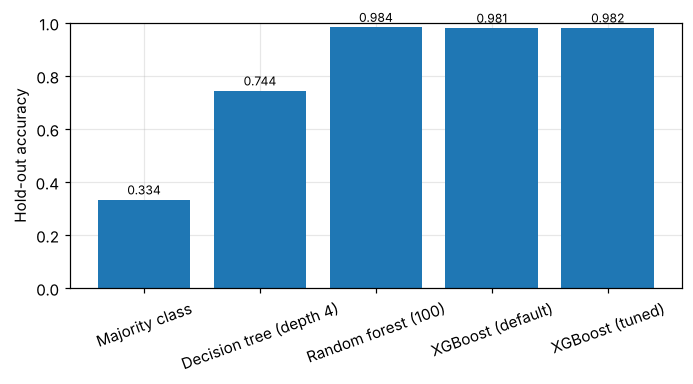

In [23]:
# 18) Comparison against reference classifiers
if ENABLE_BASELINES:
    cands = {
        "Majority class": DummyClassifier(strategy="most_frequent"),
        "Decision tree (depth 4)": DecisionTreeClassifier(max_depth=4, random_state=MODEL_SEED),
        "Random forest (100)": RandomForestClassifier(n_estimators=100, n_jobs=-1,
                                                      random_state=MODEL_SEED),
        "XGBoost (default)": X.XGBClassifier(objective="multi:softprob", num_class=NCLS,
                                             n_estimators=200, tree_method="hist", n_jobs=-1,
                                             random_state=MODEL_SEED, verbosity=0),
        "XGBoost (tuned)": None,
    }
    rows = []
    for name, mdl in cands.items():
        if mdl is None:
            pr = pred
        else:
            mdl.fit(Str, ytr); pr = mdl.predict(Ste)
        rows.append({"model": name, "accuracy": accuracy_score(yte, pr),
                     "balanced_accuracy": balanced_accuracy_score(yte, pr),
                     "f1_macro": f1_score(yte, pr, average="macro"),
                     "cohen_kappa": cohen_kappa_score(yte, pr)})
    comp = pd.DataFrame(rows)
    save_table(comp, "tbl_5_27_model_comparison",
               "Table 5.27 Comparison with reference classifiers on the test set")
    display(comp)
    fig, ax = plt.subplots(figsize=(6.4, 3.6))
    ax.bar(comp["model"], comp["accuracy"])
    ax.set_ylabel("Hold-out accuracy"); ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=20)
    for i, v in enumerate(comp["accuracy"]): ax.text(i, v + 0.02, f"{v:.3f}", ha="center", fontsize=8)
    save_fig(fig, "fig_5_11_model_comparison", "Figure 5.11 Comparison against reference classifiers")
    RESULTS["model_comparison"] = comp.to_dict(orient="records")

## 19) Accuracy against flash footprint

The best configuration at each depth is trained once to `SWEEP_MAX_ROUNDS` and then truncated,
so the first `R` boosting rounds form an `R`-round model. Truncation makes the sweep exact and
avoids retraining at every point.

truncation front over depths: {2: 0.3, 3: 0.3, 4: 0.3, 5: 0.3, 6: 0.3}


,config,rounds,trees,nodes,c_KiB,accuracy,f1_macro
0,depth2,20,60,420,12.7,0.8555,0.8561
1,depth2,40,120,838,23.8,0.8848,0.8852
2,depth2,60,180,1258,35.1,0.8984,0.8985
3,depth2,80,240,1674,46.7,0.9080,0.9080
4,depth2,100,300,2092,58.2,0.9189,0.9186
5,depth2,120,360,2510,69.8,0.9245,0.9242
6,depth2,140,420,2928,81.4,0.9313,0.9310
7,depth2,160,480,3348,93.1,0.9361,0.9357
8,depth2,180,540,3764,104.6,0.9389,0.9386
9,depth2,200,600,4184,116.3,0.9408,0.9405


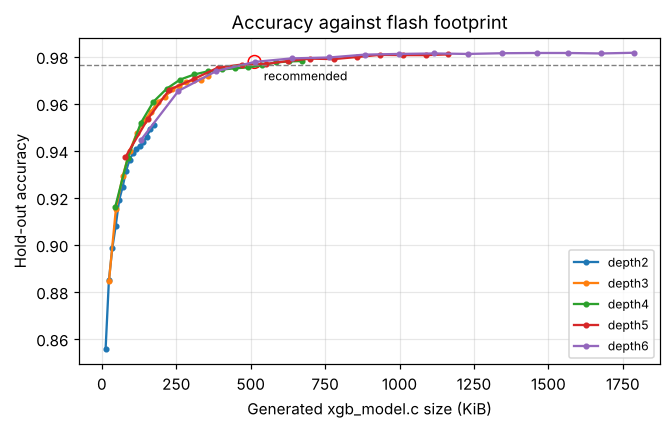

best accuracy on test = 0.9816 | target (>= best-0.005) = 0.9766
RECOMMENDED: depth6 {'max_depth': 6, 'learning_rate': 0.3, 'min_child_weight': 1, 'reg_lambda': 2.0} @ 80 rounds | 513.2 KB | acc=0.9777
MAX ACCURACY: depth6 {'max_depth': 6, 'learning_rate': 0.3, 'min_child_weight': 1, 'reg_lambda': 2.0} @ 300 rounds | 1786.2 KB | acc=0.9816


In [24]:
# 19) Round sweep by truncation -> Pareto front
tmp = os.path.join(OUT_DIR, "_tmp"); front, trained = [], {}
# One configuration per swept depth, all at the same rate and child weight, so the front
# compares depths and round counts and nothing else. Reusing the grid winner per depth would
# tie the front to near-equal grid entries (child weight 1 or 5 at depth 4 differ by 0.0001).
sweep_cfg = {d: {"max_depth": d, "learning_rate": SWEEP_LR,
                 "min_child_weight": 1, "reg_lambda": 2.0} for d in SWEEP_DEPTHS}
print("truncation front over depths:", {d: sweep_cfg[d]["learning_rate"] for d in sweep_cfg})

for d, p in sweep_cfg.items():
    m = make_clf(p, SWEEP_MAX_ROUNDS); m.fit(Str, ytr)
    b = m.get_booster(); fd = b.get_dump(dump_format="json"); BASE = compute_base(b, Str[0])
    trained[d] = (p, b, fd, BASE)
    for R in range(SWEEP_STEP, SWEEP_MAX_ROUNDS + 1, SWEEP_STEP):
        pr = b.predict(dm_te, iteration_range=(0, R)).argmax(1)
        csz, nn, nt = export_c(fd, R, MN, MX, WT, BASE, tmp, NFEAT)
        front.append((d, p, R, nt, nn, csz, accuracy_score(yte, pr),
                      f1_score(yte, pr, average="macro")))
shutil.rmtree(tmp, ignore_errors=True)

front_df = pd.DataFrame([(f"depth{d}", R, nt, nn, round(csz, 1), round(acc, 4), round(f1, 4))
                         for (d, p, R, nt, nn, csz, acc, f1) in front],
                        columns=["config", "rounds", "trees", "nodes", "c_KiB", "accuracy", "f1_macro"])
save_table(front_df, "tbl_5_28_pareto_sweep",
           "Table 5.28 Accuracy and generated C size against boosting rounds")
display(front_df.head(12))

best_acc = max(f[6] for f in front); target = best_acc - ACC_TOLERANCE
recommended = min((f for f in front if f[6] >= target), key=lambda f: f[5])
maxacc = max(front, key=lambda f: (f[6], -f[5]))

fig, ax = plt.subplots(figsize=(6.2, 4.0))
for cfg, g in front_df.groupby("config"):
    ax.plot(g["c_KiB"], g["accuracy"], "o-", ms=3, label=cfg)
ax.axhline(target, ls="--", lw=0.9, color="grey")
ax.annotate("recommended", (recommended[5], recommended[6]),
            textcoords="offset points", xytext=(6, -12), fontsize=8)
ax.scatter([recommended[5]], [recommended[6]], s=70, facecolors="none", edgecolors="red")
ax.set_xlabel("Generated xgb_model.c size (KiB)"); ax.set_ylabel("Hold-out accuracy")
ax.set_title("Accuracy against flash footprint"); ax.legend(fontsize=8)
save_fig(fig, "fig_5_12_pareto", "Figure 5.12 Accuracy against generated model size")

print(f"best accuracy on test = {best_acc:.4f} | target (>= best-{ACC_TOLERANCE}) = {target:.4f}")
print(f"RECOMMENDED: depth{recommended[0]} {recommended[1]} @ {recommended[2]} rounds "
      f"| {recommended[5]:.1f} KB | acc={recommended[6]:.4f}")
print(f"MAX ACCURACY: depth{maxacc[0]} {maxacc[1]} @ {maxacc[2]} rounds "
      f"| {maxacc[5]:.1f} KB | acc={maxacc[6]:.4f}")
RESULTS["recommended"] = {"depth": recommended[0], "params": recommended[1],
                          "rounds": recommended[2], "accuracy": recommended[6],
                          "c_KB": round(recommended[5], 1)}
RESULTS["max_accuracy"] = {"depth": maxacc[0], "params": maxacc[1], "rounds": maxacc[2],
                           "accuracy": maxacc[6], "c_KB": round(maxacc[5], 1)}

## 19a) Selecting under a flash budget rather than on accuracy

The cross-validated winner of the extended grid is a deep ensemble that exports to several
megabytes and cannot be flashed alongside the TLS stack. The deployment point is therefore the
most accurate configuration whose generated source fits `FLASH_BUDGET_KB`, and the unconstrained
winner is retained beside it so that the price of the constraint is stated rather than assumed.


In [25]:
# 19a) Flash-constrained selection over the truncation front
front_df["fits_budget"] = front_df["c_KiB"] <= FLASH_BUDGET_KB
under = front_df[front_df["fits_budget"]]
if len(under):
    dep = under.sort_values("accuracy", ascending=False).iloc[0]
    print(f"deployment point under {FLASH_BUDGET_KB} KiB: {dep['config']} @ {dep['rounds']} rounds"
          f" | {dep['c_KiB']} KiB | acc={dep['accuracy']:.4f}")
    RESULTS["deployment_point"] = dep.to_dict()
else:
    print(f"no configuration on the front fits {FLASH_BUDGET_KB} KiB; widen the sweep")

budget_rows = []
for budget in (128, 256, 512, 1024, 10**6):
    u = front_df[front_df["c_KiB"] <= budget]
    if not len(u): continue
    b = u.sort_values("accuracy", ascending=False).iloc[0]
    budget_rows.append({"flash_budget_KiB": budget if budget < 10**6 else "unbounded",
                        "configuration": b["config"], "rounds": int(b["rounds"]),
                        "c_KiB": b["c_KiB"], "hold_out_accuracy": b["accuracy"]})
budget_tbl = pd.DataFrame(budget_rows)
save_table(budget_tbl, "tbl_5_29_flash_budget",
           "Table 5.29 Best configuration available under a flash budget")
display(budget_tbl)
RESULTS["flash_budget"] = budget_rows


deployment point under 256 KiB: depth4 @ 100 rounds | 218.8 KiB | acc=0.9664


,flash_budget_KiB,configuration,rounds,c_KiB,hold_out_accuracy
0,128,depth3,100,117.8,0.9475
1,256,depth4,100,218.8,0.9664
2,512,depth5,120,471.4,0.9766
3,1024,depth6,160,998.1,0.9811
4,unbounded,depth6,300,1786.2,0.9816


In [26]:
# 19b) The confusion matrix restated as update-policy outcomes
cm = cm_te
totals = cm.sum(1)
policy = pd.DataFrame([
    {"policy outcome": "correct action", "true tier": "any",
     "records": int(np.trace(cm)), "rate_%": 100 * np.trace(cm) / cm.sum()},
    {"policy outcome": "missed switch (Bad read as Good)", "true tier": "Bad",
     "records": int(cm[2, 0]), "rate_%": 100 * cm[2, 0] / totals[2]},
    {"policy outcome": "spurious switch (Good read as Bad)", "true tier": "Good",
     "records": int(cm[0, 2]), "rate_%": 100 * cm[0, 2] / totals[0]},
    {"policy outcome": "under-reaction (Bad read as Medium)", "true tier": "Bad",
     "records": int(cm[2, 1]), "rate_%": 100 * cm[2, 1] / totals[2]},
    {"policy outcome": "over-reaction (Medium read as Bad)", "true tier": "Medium",
     "records": int(cm[1, 2]), "rate_%": 100 * cm[1, 2] / totals[1]},
    {"policy outcome": "needless adjustment (Good read as Medium)", "true tier": "Good",
     "records": int(cm[0, 1]), "rate_%": 100 * cm[0, 1] / totals[0]},
    {"policy outcome": "missed adjustment (Medium read as Good)", "true tier": "Medium",
     "records": int(cm[1, 0]), "rate_%": 100 * cm[1, 0] / totals[1]},
])
save_table(policy, "tbl_5_30_policy_outcomes",
           "Table 5.30 Test-set errors expressed as update-policy outcomes")
display(policy)
RESULTS["policy_outcomes"] = policy.to_dict(orient="records")


,policy outcome,true tier,records,rate_%
0,correct action,any,17388,98.170732
1,missed switch (Bad read as Good),Bad,0,0.000000
2,spurious switch (Good read as Bad),Good,0,0.000000
3,under-reaction (Bad read as Medium),Bad,84,1.422282
4,over-reaction (Medium read as Bad),Medium,88,1.492031
5,needless adjustment (Good read as Medium),Good,65,1.100203
6,missed adjustment (Medium read as Good),Medium,87,1.475076


## 19c) The deployment point on its own

Sections 12 to 17c describe the cross-validated winner of the grid. The model that ships is
the one selected under `FLASH_BUDGET_KB` in 19a, so its own figures are computed here: the
hold-out and out-of-fold metrics, the confusion matrix, the per-class report, the update-policy
outcomes beside those of the winner, the error breakdown, transfer to a withheld band, and the
exported `xgb_model.c` / `xgb_model.h`. The hold-out prediction truncates the swept ensemble at
the selected round count, exactly as the exporter does.


deployment point: depth 4, 100 rounds, params {'max_depth': 4, 'learning_rate': 0.3, 'min_child_weight': 1, 'reg_lambda': 2.0}


,stage,accuracy,balanced_accuracy,f1_macro,f1_weighted,cohen_kappa,mcc,log_loss
0,cross-validation (out-of-fold),0.965856,0.965843,0.965761,0.965769,0.948783,0.948830,NaN
1,hold-out test,0.966350,0.966333,0.966186,0.966195,0.949525,0.949673,0.105192


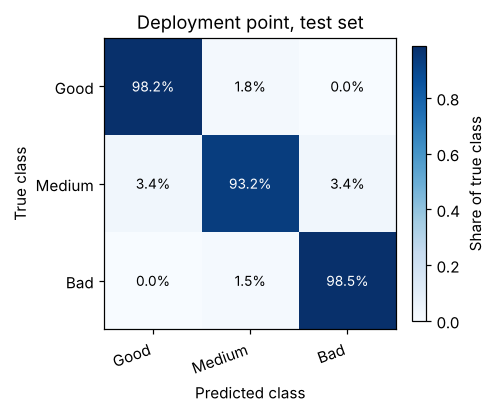

,class,precision,recall,f1_score,support,roc_auc
0,Good,0.966200,0.982227,0.974148,5908.00000,0.998685
1,Medium,0.965905,0.931841,0.948567,5898.00000,0.994930
2,Bad,0.966922,0.984931,0.975843,5906.00000,0.998840
3,accuracy,0.966350,0.966350,0.966350,0.96635,NaN
4,macro avg,0.966342,0.966333,0.966186,17712.00000,NaN
5,weighted avg,0.966343,0.966350,0.966195,17712.00000,NaN


,policy outcome,true tier,deployment_records,deployment_rate_%,cv_winner_rate_%
0,correct action,any,17116,96.635050,98.170732
1,missed switch (Bad read as Good),Bad,0,0.000000,0.000000
2,spurious switch (Good read as Bad),Good,0,0.000000,0.000000
3,under-reaction (Bad read as Medium),Bad,89,1.506942,1.422282
4,over-reaction (Medium read as Bad),Medium,199,3.374025,1.492031
5,needless adjustment (Good read as Medium),Good,105,1.777251,1.100203
6,missed adjustment (Medium read as Good),Medium,203,3.441845,1.475076


,held_out_band,accuracy,balanced_accuracy,f1_macro
0,20 MHz,0.748188,0.748074,0.742922
1,40 MHz,0.873937,0.873855,0.871624
2,90 MHz,0.809701,0.809686,0.806740
3,180 MHz,0.810811,0.810758,0.810436
4,360 MHz,0.788476,0.788281,0.774152


exported chapter5_out/models/deployment_depth4_r100: 300 trees, 8034 nodes, 218.8 KiB | test acc 0.9664 | LOBO mean 0.8062


In [27]:
# 19c) Evaluate and export the flash-budget deployment point
dep_depth = int(str(dep["config"]).replace("depth", ""))
dep_rounds = int(dep["rounds"])
dep_params, dep_booster, dep_dump, dep_base = trained[dep_depth]
print(f"deployment point: depth {dep_depth}, {dep_rounds} rounds, params {dep_params}")

# Test set: truncate the swept ensemble at the selected round count
proba_dep = dep_booster.predict(dm_te, iteration_range=(0, dep_rounds))
pred_dep = proba_dep.argmax(1)
m_dep_te = metric_block(yte, pred_dep, proba_dep, tag="deployment_hold_out")

# Out-of-fold on the training partition, same folds as the search
oof_dep = cross_val_predict(make_clf(dep_params, dep_rounds), Str, ytr, cv=skf, n_jobs=1)
m_dep_cv = metric_block(ytr, oof_dep, tag="deployment_cross_validation")
dep_metrics = pd.DataFrame([{"stage": "cross-validation (out-of-fold)", **m_dep_cv},
                            {"stage": "hold-out test", **m_dep_te}])
save_table(dep_metrics, "tbl_5_31_deployment_metrics",
           f"Table 5.31 Headline metrics of the deployment point (depth {dep_depth}, {dep_rounds} rounds)")
display(dep_metrics)

cm_dep = confusion_matrix(yte, pred_dep, labels=range(NCLS))
save_table(pd.DataFrame(cm_dep, index=[f"true {c}" for c in CLASS_NAMES],
                        columns=[f"pred {c}" for c in CLASS_NAMES]).reset_index(),
           "tbl_5_32_deployment_confusion",
           "Table 5.32 Confusion matrix of the deployment point on the test set", index=False)
plot_confusion(cm_dep, "Deployment point, test set", "fig_5_16_deployment_confusion",
               "Figure 5.16 Row-normalised confusion matrix of the deployment point", normalise=True)

rep_dep = pd.DataFrame(classification_report(yte, pred_dep, target_names=CLASS_NAMES,
                                             output_dict=True, zero_division=0)).T.reset_index()
rep_dep.columns = ["class", "precision", "recall", "f1_score", "support"]
Yb_dep = label_binarize(yte, classes=range(NCLS))
auc_dep = {c: auc(*roc_curve(Yb_dep[:, i], proba_dep[:, i])[:2]) for i, c in enumerate(CLASS_NAMES)}
rep_dep["roc_auc"] = rep_dep["class"].map(auc_dep)
save_table(rep_dep, "tbl_5_33_deployment_report",
           "Table 5.33 Per-class precision, recall, F1 and ROC AUC of the deployment point")
display(rep_dep)

def policy_table(cm):
    t = cm.sum(1)
    rows = [("correct action", "any", np.trace(cm), np.trace(cm) / cm.sum()),
            ("missed switch (Bad read as Good)", "Bad", cm[2, 0], cm[2, 0] / t[2]),
            ("spurious switch (Good read as Bad)", "Good", cm[0, 2], cm[0, 2] / t[0]),
            ("under-reaction (Bad read as Medium)", "Bad", cm[2, 1], cm[2, 1] / t[2]),
            ("over-reaction (Medium read as Bad)", "Medium", cm[1, 2], cm[1, 2] / t[1]),
            ("needless adjustment (Good read as Medium)", "Good", cm[0, 1], cm[0, 1] / t[0]),
            ("missed adjustment (Medium read as Good)", "Medium", cm[1, 0], cm[1, 0] / t[1])]
    return pd.DataFrame([{"policy outcome": a, "true tier": b, "records": int(n), "rate_%": 100 * r}
                         for a, b, n, r in rows])

pol = policy_table(cm_dep).rename(columns={"records": "deployment_records",
                                           "rate_%": "deployment_rate_%"})
pol["cv_winner_rate_%"] = policy_table(cm_te)["rate_%"]   # cm_te: section 12, the grid winner
save_table(pol, "tbl_5_34_deployment_policy",
           "Table 5.34 Test-set errors of the deployment point and the grid winner as update-policy outcomes")
display(pol)

err_dep = meta_te.copy(); err_dep["correct"] = pred_dep == yte
for key, name, caption in [
        ("cipher", "tbl_5_35_deployment_by_cipher", "Table 5.35 Deployment-point accuracy per cipher suite"),
        ("band", "tbl_5_36_deployment_by_band", "Table 5.36 Deployment-point accuracy per clock band"),
        ("payload_size", "tbl_5_37_deployment_by_payload", "Table 5.37 Deployment-point accuracy per payload size")]:
    t = (err_dep.groupby(key)["correct"].agg(["mean", "count"])
            .rename(columns={"mean": "accuracy", "count": "records"}).reset_index())
    if key == "cipher": t = t.sort_values("accuracy")
    save_table(t, name, caption)

lobo_dep = []
for b in [b for b in DATASETS if b in set(df["band"])]:
    msk = (df["band"] == b).to_numpy()
    mdl = make_clf(dep_params, dep_rounds)
    mdl.fit(apply_scaler(Xdf[~msk], MN, MX, WT), yy[~msk])
    pb = mdl.predict(apply_scaler(Xdf[msk], MN, MX, WT))
    lobo_dep.append({"held_out_band": b, "accuracy": accuracy_score(yy[msk], pb),
                     "balanced_accuracy": balanced_accuracy_score(yy[msk], pb),
                     "f1_macro": f1_score(yy[msk], pb, average="macro")})
lobo_dep = pd.DataFrame(lobo_dep)
save_table(lobo_dep, "tbl_5_38_deployment_cross_band",
           "Table 5.38 Leave-one-band-out accuracy of the deployment point")
display(lobo_dep)

dep_dir = os.path.join(MODEL_DIR, f"deployment_depth{dep_depth}_r{dep_rounds:03d}")
dep_kb, dep_nodes, dep_trees = export_c(dep_dump, dep_rounds, MN, MX, WT, dep_base,
                                        dep_dir, NFEAT, cols=COLS)
RESULTS["deployment"] = {"depth": dep_depth, "rounds": dep_rounds, "params": dep_params,
                         "trees": dep_trees, "nodes": dep_nodes, "c_KiB": round(dep_kb, 1),
                         "hold_out": m_dep_te, "cross_validation": m_dep_cv,
                         "roc_auc": auc_dep, "lobo_mean": float(lobo_dep["accuracy"].mean()),
                         "export_dir": os.path.relpath(dep_dir, OUT_DIR)}
print(f"exported {dep_dir}: {dep_trees} trees, {dep_nodes} nodes, {dep_kb:.1f} KiB | "
      f"test acc {m_dep_te['accuracy']:.4f} | LOBO mean {lobo_dep['accuracy'].mean():.4f}")


In [28]:
# 20) Export C/H for both operating points, write the report bundle
def export_point(tag, d, R):
    p, b, fd, BASE = trained[d]
    outdir = os.path.join(MODEL_DIR, f"{tag}_depth{d}_r{R:03d}")
    export_c(fd, R, MN, MX, WT, BASE, outdir, NFEAT, cols=COLS)
    return outdir, p

rec_dir, rec_p = export_point("recommended", recommended[0], recommended[2])
max_dir, max_p = export_point("maxacc", maxacc[0], maxacc[2])

if INCLUDE_BASELINE_C:
    bl = X.XGBClassifier(objective="multi:softprob", num_class=NCLS, n_estimators=200,
                         tree_method="hist", n_jobs=-1, random_state=MODEL_SEED,
                         eval_metric="mlogloss", verbosity=0)
    bl.fit(Str, ytr); bb = bl.get_booster()
    bacc = accuracy_score(yte, bb.predict(dm_te).argmax(1))
    bsz, _, _ = export_c(bb.get_dump(dump_format="json"), 200, MN, MX, WT,
                         compute_base(bb, Str[0]),
                         os.path.join(MODEL_DIR, "baseline_depth6_r200"), NFEAT, cols=COLS)
    RESULTS["baseline_c"] = {"accuracy": round(float(bacc), 4), "c_KB": round(bsz, 1)}
    print(f"baseline depth6/200: acc={bacc:.4f} .c={bsz:.1f} KB")

RESULTS["dataset"] = {"records": int(len(df)), "features": FEATS,
                      "label_scope": LABEL_SCOPE, "bands": sorted(df["band"].unique().tolist()),
                      "ciphers": sorted(df["cipher"].unique().tolist()),
                      "energy_proxy_mW": P_ACTIVE_MW}
RESULTS["feature_order"] = COLS
json.dump(RESULTS, open(os.path.join(OUT_DIR, "results.json"), "w"), indent=2, ensure_ascii=False)

head = (("> **Smoke-test run.** QUICK_MODE was enabled, so the grid and the number of boosting "
         "rounds were reduced. Do not quote these figures.\n\n" if QUICK_MODE else "") +
        "# Chapter 5 machine-learning results\n\n"
        f"Corpus: {len(df):,} records, {len(FEATS)} features, "
        f"{df['cipher'].nunique()} cipher suites, {df['band'].nunique()} frequency bands. "
        f"Labels: {LABEL_SCOPE} terciles of the weighted composite score. "
        f"Split: {int((1-TEST_SIZE)*100)}/{int(TEST_SIZE*100)} stratified, seed {SPLIT_SEED}; "
        f"{CV_FOLDS}-fold stratified cross-validation on the training partition.\n\n"
        f"Deployment point (best under the {FLASH_BUDGET_KB} KiB flash budget): depth {dep_depth}, "
        f"{dep_rounds} rounds, {dep_kb:.1f} KiB of C; test accuracy {m_dep_te['accuracy']:.4f}, "
        f"macro F1 {m_dep_te['f1_macro']:.4f}, Cohen kappa {m_dep_te['cohen_kappa']:.4f}. "
        f"Grid winner (Sections 12 to 17c): test accuracy {RESULTS['hold_out_test']['accuracy']:.4f}, "
        f"macro F1 {RESULTS['hold_out_test']['f1_macro']:.4f}, "
        f"Cohen kappa {RESULTS['hold_out_test']['cohen_kappa']:.4f}.\n\n---\n")
open(os.path.join(OUT_DIR, "chapter5_results.md"), "w").write(head + "\n".join(REPORT))

zip_path = "chapter5_bundle.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, fs in os.walk(OUT_DIR):
        for fn in fs:
            fp = os.path.join(root, fn); z.write(fp, os.path.relpath(fp, OUT_DIR))
print("bundle:", zip_path, round(os.path.getsize(zip_path) / 1024, 1), "KB")
if IN_COLAB:
    from google.colab import files as _f; _f.download(zip_path)
print(f"\nDone. Copy the {os.path.basename(dep_dir)} folder (xgb_model.c + xgb_model.h) into the firmware tree,")
print("and make sure the on-device features[] array follows this order:")
print(COLS)

baseline depth6/200: acc=0.9809 .c=1197.2 KB


bundle: chapter5_bundle.zip 3379.7 KB

Done. Copy the deployment_depth4_r100 folder (xgb_model.c + xgb_model.h) into the firmware tree,
and make sure the on-device features[] array follows this order:
['lat_per_byte', 'E_lat_per_byte', 'cycles_per_bit', 'throughput', 'Energy', 'stack_per_msg', 'latency', 'E_latency', 'cycles_mean', 'payload_size', 'heap_per_msg', 'Flash_used', 'Ex_code', 'rodata', 'total_memory', 'cv_latency', 'lat_per_byte_std', 'E_lat_per_byte_std']
